# Predicting Term Deposit Subscription to Improve Bank Marketing Targeting
## Team 10 High Five
Daniel Li, Yerim Mo, Celeste Wang, Chrissy Wang, Yuri Yang

ISOM 672 Introduction to Business Analytics

This notebook follows CRISP-DM: Business Understanding, Data Understanding, Data Preparation, Modeling, Evaluation, and Deployment. It uses one shared chronological split and presents the group's final 15-predictor models.

**Run instructions:** Keep `bank-additional-full.csv` beside this notebook and run all cells in order. Change `DATA_PATH` in the loading cell if needed. All preprocessing and models are fitted on training records only. Validation supports hyperparameter selection; the later test period provides descriptive evaluation. Keep the `reference_scores` folder beside the notebook: the final k-NN export is used for the business comparison, and the other teammate handoffs support reproducibility checks. Model fitting uses the raw dataset only. The executed notebook uses Python 3.12 and scikit-learn 1.9.0.

## 1 Business Understanding
The bank has more eligible customers than its staff can contact when promoting term deposits. The decision is **which customers to prioritize under a limited contact budget**. We use customer information and prior campaign history to estimate subscription scores and rank contact opportunities.

The target `y` is binary, so the modeling task is supervised classification. The business action is ranking at a fixed capacity rather than classifying with a universal 0.50 cutoff. The proposal’s example of 10,000 eligible customers and 1,000 contacts is illustrative. We use an illustrative 10% evaluation capacity, rounded up consistently, and show 5%, 20%, and exactly 1,000 records as descriptive scenarios. Historical ranking performance can measure targeting efficiency but cannot establish incremental subscriptions caused by outreach.

## 2 Data Understanding
### Data Description
Source: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing). We use **bank-additional-full.csv**, containing 41,188 campaign records and 20 original predictors. Records follow date order from May 2008 through November 2010. A record may involve multiple contacts and is not a unique customer or a single independent call.

Numerical original inputs: age, duration, campaign, pdays, previous, emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed. Categorical inputs: job, marital, education, default, housing, loan, contact, month, day_of_week, poutcome. The target `y` indicates term-deposit subscription. `unknown` is an explicit category; `pdays=999` means no previous contact. `duration` is unavailable before contact.

In [1]:
############################## Code Sources & Imports ################################

# Code was developed based on Python examples and course materials
# provided in Introduction to Business Data Analytics.
# Scikit-learn documentation was also referenced:
# https://scikit-learn.org/stable/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json, warnings, hashlib
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import linear_model
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils import resample
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, roc_curve, confusion_matrix,
    ConfusionMatrixDisplay, classification_report)
EXPORT_RESULTS = True
OUTPUT_DIR = Path('team10_results')
OUTPUT_DIR.mkdir(exist_ok=True)
print('scikit-learn:', sklearn.__version__)

from IPython.display import display, Markdown, Image
from threadpoolctl import threadpool_limits
thread_limits = threadpool_limits(limits=4)


scikit-learn: 1.9.0


In [2]:
DATA_PATH = Path('bank-additional-full.csv')  # Change only this path if needed.
df = pd.read_csv(DATA_PATH, sep=';')
assert df.shape == (41188, 21)
print('Dataset shape:', df.shape)
print('Source SHA-256:', hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
display(df.head())

Dataset shape: (41188, 21)
Source SHA-256: 74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Dataset overview

In [3]:
############################## Dataset Overview ################################

print("Number of Observations:", df.shape[0])
print("Number of Variables:", df.shape[1])

print("\nVariables:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Number of Observations: 41188
Number of Variables: 21

Variables:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Data Types:
age                 int64
job                   str
marital               str
education             str
default               str
housing               str
loan                  str
contact               str
month                 str
day_of_week           str
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome              str
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                     str
dtype: object


### Missing values and duplicate rows

In [4]:
############################## Data Quality ################################

# Missing values
print("Missing Values:")
print(df.isnull().sum())

# Duplicate rows
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

Missing Values:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Number of Duplicate Rows:
12


### Unknown categories

In [5]:
############################## Unknown Categories ################################

categorical_cols = df.select_dtypes(include='object').columns

unknown_summary = []

for col in categorical_cols:
    unknown_count = (df[col] == 'unknown').sum()

    if unknown_count > 0:
        unknown_summary.append({
            'Variable': col,
            'Unknown Count': unknown_count,
            'Unknown Percentage': round(
                unknown_count / len(df) * 100, 2
            )
        })

unknown_summary = pd.DataFrame(unknown_summary)

display(unknown_summary)

/var/folders/6d/q_9_q8vd1wx5ykvsxqmgv0n80000gn/T/ipykernel_19412/207895335.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include='object').columns


,Variable,Unknown Count,Unknown Percentage
0,job,330,0.80
1,marital,80,0.19
2,education,1731,4.20
3,default,8597,20.87
4,housing,990,2.40
5,loan,990,2.40


### Target distribution

In [6]:
############################## Target Distribution ################################

target_summary = pd.DataFrame({
    'Count': df['y'].value_counts(),
    'Percentage': (
        df['y'].value_counts(normalize=True) * 100
    ).round(2)
})

display(target_summary)

,Count,Percentage
y,,
no,36548,88.73
yes,4640,11.27


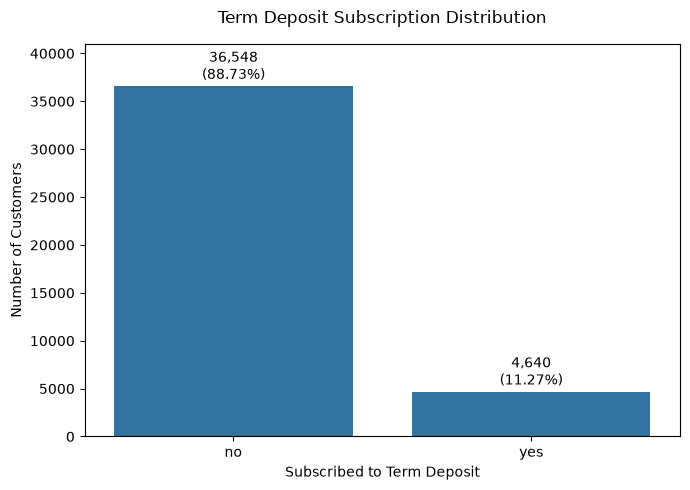

In [7]:
############################## Target Distribution Visualization ################################

target_counts = df['y'].value_counts().reindex(['no', 'yes'])
target_pct = df['y'].value_counts(normalize=True).reindex(['no', 'yes']) * 100

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x='y',
    order=['no', 'yes']
)

plt.title('Term Deposit Subscription Distribution', pad=15)
plt.xlabel('Subscribed to Term Deposit')
plt.ylabel('Number of Customers')

for i, count in enumerate(target_counts):
    pct = target_pct.iloc[i]

    ax.text(
        i,
        count + 300,
        f'{count:,}\n({pct:.2f}%)',
        ha='center',
        va='bottom'
    )

ax.set_ylim(0, 41000)

plt.tight_layout()
plt.show()

### Numerical summaries

In [8]:
############################## Numerical Predictor Summary ################################

numerical_cols = [
    'age',
    'duration',
    'campaign',
    'pdays',
    'previous',
    'emp.var.rate',
    'cons.price.idx',
    'cons.conf.idx',
    'euribor3m',
    'nr.employed'
]

numerical_summary = (
    df[numerical_cols]
    .describe()
    .T[['min', 'max', 'mean', 'std']]
    .round(2)
)

display(numerical_summary)

,min,max,mean,std
age,17.00,98.00,40.02,10.42
duration,0.00,4918.00,258.29,259.28
campaign,1.00,56.00,2.57,2.77
pdays,0.00,999.00,962.48,186.91
previous,0.00,7.00,0.17,0.49
emp.var.rate,-3.40,1.40,0.08,1.57
cons.price.idx,92.20,94.77,93.58,0.58
cons.conf.idx,-50.80,-26.90,-40.50,4.63
euribor3m,0.63,5.04,3.62,1.73
nr.employed,4963.60,5228.10,5167.04,72.25


### Numerical predictors by target

In [9]:
############################## Numerical Predictors by Subscription ################################

numerical_by_target = (
    df.groupby('y')[numerical_cols]
    .mean()
    .T
    .round(2)
)

numerical_by_target['Difference (Yes - No)'] = (
    numerical_by_target['yes'] - numerical_by_target['no']
).round(2)

display(numerical_by_target)

y,no,yes,Difference (Yes - No)
age,39.91,40.91,1.00
duration,220.84,553.19,332.35
campaign,2.63,2.05,-0.58
pdays,984.11,792.04,-192.07
previous,0.13,0.49,0.36
emp.var.rate,0.25,-1.23,-1.48
cons.price.idx,93.60,93.35,-0.25
cons.conf.idx,-40.59,-39.79,0.80
euribor3m,3.81,2.12,-1.69
nr.employed,5176.17,5095.12,-81.05


### Special meaning of pdays

In [10]:
############################## Inspect pdays ################################

pdays_999 = (df['pdays'] == 999).sum()
pdays_actual = (df['pdays'] != 999).sum()

print("Customers with pdays = 999 (not previously contacted):")
print(f"{pdays_999:,} ({pdays_999 / len(df) * 100:.2f}%)")

print("\nCustomers with an actual previous-contact gap:")
print(f"{pdays_actual:,} ({pdays_actual / len(df) * 100:.2f}%)")

Customers with pdays = 999 (not previously contacted):
39,673 (96.32%)

Customers with an actual previous-contact gap:
1,515 (3.68%)


In [11]:
############################## pdays for Previously Contacted Customers ################################

previously_contacted_df = df[df['pdays'] != 999]

pdays_by_target = (
    previously_contacted_df
    .groupby('y')['pdays']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

display(pdays_by_target)

,count,mean,median
y,,,
no,548,6.19,6.0
yes,967,5.91,6.0


### Categorical subscription rates

In [12]:
############################## Categorical Predictors by Subscription ################################

categorical_predictors = [
    'job',
    'marital',
    'education',
    'default',
    'housing',
    'loan',
    'contact',
    'month',
    'day_of_week',
    'poutcome'
]

for col in categorical_predictors:
    
    summary = (
        df.groupby(col)['y']
        .apply(lambda x: (x == 'yes').mean() * 100)
        .sort_values(ascending=False)
        .round(2)
    )
    
    print(f"\n{col} - Subscription Rate (%)")
    print(summary)


job - Subscription Rate (%)
job
student          31.43
retired          25.23
unemployed       14.20
admin.           12.97
management       11.22
unknown          11.21
technician       10.83
self-employed    10.49
housemaid        10.00
entrepreneur      8.52
services          8.14
blue-collar       6.89
Name: y, dtype: float64

marital - Subscription Rate (%)
marital
unknown     15.00
single      14.00
divorced    10.32
married     10.16
Name: y, dtype: float64

education - Subscription Rate (%)
education
illiterate             22.22
unknown                14.50
university.degree      13.72
professional.course    11.35
high.school            10.84
basic.4y               10.25
basic.6y                8.20
basic.9y                7.82
Name: y, dtype: float64

default - Subscription Rate (%)
default
no         12.88
unknown     5.15
yes         0.00
Name: y, dtype: float64

housing - Subscription Rate (%)
housing
yes        11.62
no         10.88
unknown    10.81
Name: y, dtype: float

### Category counts and response rates

In [13]:
############################## Key Categorical Variables: Count and Subscription Rate ################################

key_categorical = ['poutcome', 'contact', 'month', 'job']

for col in key_categorical:
    
    summary = df.groupby(col)['y'].agg(
        Count='count',
        Subscription_Rate=lambda x: (x == 'yes').mean() * 100
    ).round(2)
    
    summary = summary.sort_values('Subscription_Rate', ascending=False)
    
    print(f"\n{col}")
    display(summary)


poutcome


,Count,Subscription_Rate
poutcome,,
success,1373,65.11
failure,4252,14.23
nonexistent,35563,8.83



contact


,Count,Subscription_Rate
contact,,
cellular,26144,14.74
telephone,15044,5.23



month


,Count,Subscription_Rate
month,,
mar,546,50.55
dec,182,48.90
sep,570,44.91
oct,718,43.87
apr,2632,20.48
aug,6178,10.60
jun,5318,10.51
nov,4101,10.14
jul,7174,9.05



job


,Count,Subscription_Rate
job,,
student,875,31.43
retired,1720,25.23
unemployed,1014,14.20
admin.,10422,12.97
management,2924,11.22
unknown,330,11.21
technician,6743,10.83
self-employed,1421,10.49
housemaid,1060,10.00


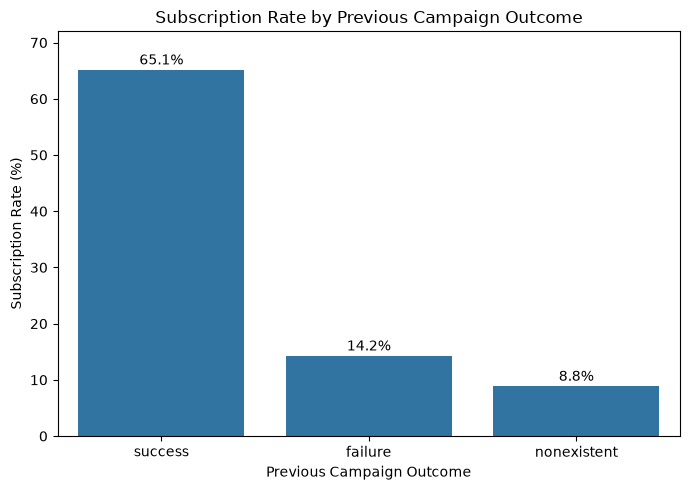

In [14]:
############################## Subscription Rate by Previous Campaign Outcome ################################

poutcome_rate = (
    df.groupby('poutcome')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=poutcome_rate.index,
    y=poutcome_rate.values
)

plt.title('Subscription Rate by Previous Campaign Outcome')
plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Subscription Rate (%)')

for i, value in enumerate(poutcome_rate.values):
    ax.text(
        i,
        value + 1,
        f'{value:.1f}%',
        ha='center'
    )

plt.ylim(0, 72)
plt.tight_layout()
plt.show()

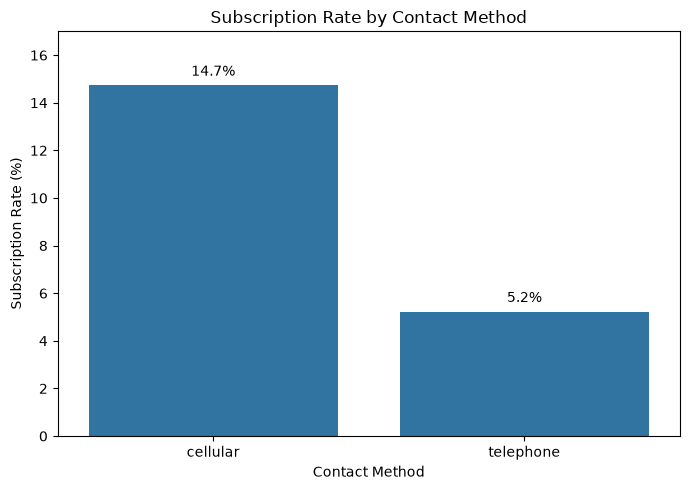

In [15]:
############################## Subscription Rate by Contact Method ################################

contact_rate = (
    df.groupby('contact')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=contact_rate.index,
    y=contact_rate.values
)

plt.title('Subscription Rate by Contact Method')
plt.xlabel('Contact Method')
plt.ylabel('Subscription Rate (%)')

for i, value in enumerate(contact_rate.values):
    ax.text(
        i,
        value + 0.4,
        f'{value:.1f}%',
        ha='center'
    )

plt.ylim(0, 17)
plt.tight_layout()
plt.show()

## 3 Data Preparation

In [16]:
############################## Start Data Preparation ################################

df_model = df.copy()

print("Starting shape:", df_model.shape)

Starting shape: (41188, 21)


### Duplicate removal

In [17]:
############################## Remove Duplicate Rows ################################

df_model = df_model.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df_model.shape)
print("Remaining duplicate rows:", df_model.duplicated().sum())

Shape after removing duplicates: (41176, 21)
Remaining duplicate rows: 0


### Duration and data leakage

In [18]:
############################## Remove Duration ################################

df_model = df_model.drop(columns=['duration'])

print("duration removed:", 'duration' not in df_model.columns)
print("Current shape:", df_model.shape)

duration removed: True
Current shape: (41176, 20)


### Engineering previous-contact information

In [19]:
############################## Feature Engineering: pdays ################################

# 1 = previously contacted, 0 = not previously contacted
df_model['previously_contacted'] = (df_model['pdays'] != 999).astype(int)

# Keep the actual number of days only for previously contacted customers
df_model['pdays_clean'] = df_model['pdays'].replace(999, np.nan)

print(df_model[['pdays', 'previously_contacted', 'pdays_clean']].head(10))

   pdays  previously_contacted  pdays_clean
0    999                     0          NaN
1    999                     0          NaN
2    999                     0          NaN
3    999                     0          NaN
4    999                     0          NaN
5    999                     0          NaN
6    999                     0          NaN
7    999                     0          NaN
8    999                     0          NaN
9    999                     0          NaN


In [20]:
############################## Verify pdays Feature Engineering ################################

print("Previously contacted:")
print(df_model['previously_contacted'].value_counts())

print("\npdays_clean summary:")
print(df_model['pdays_clean'].describe())

print("\nMissing pdays_clean values:")
print(df_model['pdays_clean'].isna().sum())

Previously contacted:
previously_contacted
0    39661
1     1515
Name: count, dtype: int64

pdays_clean summary:
count    1515.000000
mean        6.014521
std         3.824906
min         0.000000
25%         3.000000
50%         6.000000
75%         7.000000
max        27.000000
Name: pdays_clean, dtype: float64

Missing pdays_clean values:
39661


In [21]:
############################## Check pdays and poutcome Relationship ################################

pdays_poutcome_check = pd.crosstab(
    df_model['previously_contacted'],
    df_model['poutcome'],
    margins=True
)

display(pdays_poutcome_check)

poutcome,failure,nonexistent,success,All
previously_contacted,,,,
0,4110,35551,0,39661
1,142,0,1373,1515
All,4252,35551,1373,41176


### Finalizing pdays features

In [22]:
############################## Finalize pdays Features ################################

# Fill the gap with 0 when no previous contact exists.
# previously_contacted distinguishes these cases from an actual 0-day gap.
df_model['pdays_clean'] = df_model['pdays_clean'].fillna(0)

# Remove the original pdays variable so 999 is not treated as a numeric distance
df_model = df_model.drop(columns=['pdays'])

print("Original pdays removed:", 'pdays' not in df_model.columns)
print("Missing pdays_clean values:", df_model['pdays_clean'].isna().sum())

print("\nPreviously contacted counts:")
print(df_model['previously_contacted'].value_counts())

print("\npdays_clean summary:")
print(df_model['pdays_clean'].describe())

Original pdays removed: True
Missing pdays_clean values: 0

Previously contacted counts:
previously_contacted
0    39661
1     1515
Name: count, dtype: int64

pdays_clean summary:
count    41176.000000
mean         0.221294
std          1.349065
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         27.000000
Name: pdays_clean, dtype: float64


### Feature types

In [23]:
############################## Check Unknown Categories ################################

categorical_cols = df_model.select_dtypes(include=['object']).columns

unknown_summary = []

for col in categorical_cols:
    unknown_count = (df_model[col] == 'unknown').sum()
    
    if unknown_count > 0:
        unknown_summary.append({
            'Variable': col,
            'Unknown Count': unknown_count,
            'Unknown Percentage': unknown_count / len(df_model) * 100
        })

unknown_summary = pd.DataFrame(unknown_summary)

unknown_summary['Unknown Percentage'] = (
    unknown_summary['Unknown Percentage'].round(2)
)

display(unknown_summary)

/var/folders/6d/q_9_q8vd1wx5ykvsxqmgv0n80000gn/T/ipykernel_19412/701164281.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_model.select_dtypes(include=['object']).columns


,Variable,Unknown Count,Unknown Percentage
0,job,330,0.80
1,marital,80,0.19
2,education,1730,4.20
3,default,8596,20.88
4,housing,990,2.40
5,loan,990,2.40


### Retaining unknown categories

In [24]:
############################## Unknown Category Handling ################################

# Keep "unknown" as a valid category rather than removing observations.
# This avoids unnecessary data loss, especially for default,
# where 20.88% of observations are labeled as unknown.

print("Unknown values will be retained as separate categories.")
print("No rows were removed due to unknown categorical values.")
print("Current dataset shape:", df_model.shape)

Unknown values will be retained as separate categories.
No rows were removed due to unknown categorical values.
Current dataset shape: (41176, 21)


### Encoding the target

In [25]:
############################## Encode Target Variable ################################

df_model['y'] = df_model['y'].map({
    'no': 0,
    'yes': 1
})

print("Target distribution after encoding:")
print(df_model['y'].value_counts())

print("\nTarget percentages:")
print((df_model['y'].value_counts(normalize=True) * 100).round(2))

Target distribution after encoding:
y
0    36537
1     4639
Name: count, dtype: int64

Target percentages:
y
0    88.73
1    11.27
Name: proportion, dtype: float64


### Final predictor checks

In [26]:
############################## Final Predictor Check ################################

print("Final dataset shape:", df_model.shape)

print("\nFinal columns:")
print(df_model.columns.tolist())

print("\nLeakage / removed-variable check:")
print("duration included:", 'duration' in df_model.columns)
print("original pdays included:", 'pdays' in df_model.columns)

print("\nEngineered pdays features:")
print("previously_contacted included:", 'previously_contacted' in df_model.columns)
print("pdays_clean included:", 'pdays_clean' in df_model.columns)

print("\nMissing values:")
print(df_model.isna().sum().sum())

Final dataset shape: (41176, 21)

Final columns:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y', 'previously_contacted', 'pdays_clean']

Leakage / removed-variable check:
duration included: False
original pdays included: False

Engineered pdays features:
previously_contacted included: True
pdays_clean included: True

Missing values:


0


### Chronological ordering checks

In [27]:
############################## Inspect Possible Time Ordering ################################

print("First 30 months in original row order:")
print(df['month'].head(30).tolist())

print("\nLast 30 months in original row order:")
print(df['month'].tail(30).tolist())

print("\nMonth counts:")
print(df['month'].value_counts())

First 30 months in original row order:
['may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may']

Last 30 months in original row order:
['nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'nov']

Month counts:
month
may    13769
jul     7174
aug     6178
jun     5318
nov     4101
apr     2632
oct      718
sep      570
mar      546
dec      182
Name: count, dtype: int64


In [28]:
month_sequence = df['month'].drop_duplicates().tolist()

print("\nMonth sequence based on first appearance:")
print(month_sequence)


Month sequence based on first appearance:
['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'mar', 'apr', 'sep']


In [29]:
############################## Check Month Blocks ################################

month_changes = df['month'].ne(df['month'].shift())

month_blocks = df.loc[month_changes, ['month']].copy()
month_blocks['start_row'] = month_blocks.index

month_blocks['end_row'] = (
    list(month_blocks['start_row'][1:] - 1)
    + [df.index[-1]]
)

month_blocks['n_rows'] = (
    month_blocks['end_row'] - month_blocks['start_row'] + 1
)

month_blocks = month_blocks.reset_index(drop=True)

display(month_blocks)

,month,start_row,end_row,n_rows
0,may,0,7762,7763
1,jun,7763,12136,4374
2,jul,12137,18821,6685
3,aug,18822,23996,5175
4,oct,23997,24063,67
5,nov,24064,27679,3616
6,dec,27680,27689,10
7,mar,27690,27971,282
8,apr,27972,30429,2458
9,may,30430,36223,5794


### Shared Chronological Split
Preserve the deduplicated original row order and use 60% training, 20% validation, and 20% test: **24,705 / 8,235 / 8,236**. Prepared row IDs are retained through the split and identify campaign records, not unique customers. Month blocks describe chronology and do not redefine this split.

In [30]:
n = len(df_model)
train_end, validation_end = int(n*.60), int(n*.80)
train_df = df_model.iloc[:train_end].copy()
validation_df = df_model.iloc[train_end:validation_end].copy()
test_df = df_model.iloc[validation_end:].copy()
X_train, y_train = train_df.drop(columns='y'), train_df.y
X_validation, y_validation = validation_df.drop(columns='y'), validation_df.y
X_test, y_test = test_df.drop(columns='y'), test_df.y
categorical_features = [c for c in X_train.columns if not pd.api.types.is_numeric_dtype(X_train[c])]
numeric_features = [c for c in X_train.columns if c not in categorical_features]
macro_features = ['emp.var.rate','cons.price.idx','cons.conf.idx','euribor3m','nr.employed']
assert [len(y_train),len(y_validation),len(y_test)] == [24705,8235,8236]
assert np.array_equal(X_train.index,np.arange(0,24705))
assert np.array_equal(X_validation.index,np.arange(24705,32940))
assert np.array_equal(X_test.index,np.arange(32940,41176))
assert all(x.shape[1]==20 for x in [X_train,X_validation,X_test])
assert not {'duration','pdays','month_block'}.intersection(X_train.columns)
assert len(categorical_features)==len(numeric_features)==10
assert all(not x.isna().any().any() for x in [X_train,X_validation,X_test])
split_summary = pd.DataFrame([{'Set':name,'Records':len(y),'Subscribers':int(y.sum()),
    'Subscription rate':y.mean()} for name,y in [('Train',y_train),('Validation',y_validation),('Test',y_test)]])
display(split_summary)
print('Categorical:',categorical_features)
print('Numeric:',numeric_features)

,Set,Records,Subscribers,Subscription rate
0,Train,24705,1188,0.048087
1,Validation,8235,912,0.110747
2,Test,8236,2539,0.308281


Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numeric: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'pdays_clean']


### Preprocessing policy
Encoding and scaling learn only from training records. k-NN uses numeric standardization, one-hot encoding, and training-only positive-class oversampling. Its final preprocessing is fitted on the oversampled training distribution to preserve the group’s implementation. LR uses numeric standardization and one-hot encoding fitted on original training records. The tree uses one-hot encoding and numeric passthrough. Unknown categories remain explicit when observed during training; categories absent from training have no learned category-specific effect.

## 4 Modeling
We compare Logistic Regression, k-NN and Decision Tree. All final models exclude five macroeconomic predictors: `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, and `nr.employed`. The prepared dataset contains 20 predictors; the final model comparison uses 15 original predictors before encoding.

The primary selection objective is yield in the highest-scoring validation slice. LR and DT select 824 validation records. The supplied k-NN search uses 823 records (floor 10%) and score-only ordering. We preserve that documented selection protocol and also report the common 824-record ID-based rule; test comparisons use the common rule for all models. Classification diagnostics at a 0.50 threshold are separate from contact-capacity evaluation.

In [31]:
############################## Define Evaluation Metrics ################################

def classification_metrics(actual, predicted, probability):
    return {
        'Accuracy': accuracy_score(actual, predicted),
        'Precision': precision_score(actual, predicted, zero_division=0),
        'Recall': recall_score(actual, predicted, zero_division=0),
        'F1': f1_score(actual, predicted, zero_division=0),
        'ROC-AUC': roc_auc_score(actual, probability),
        'Average Precision': average_precision_score(actual, probability)
    }


def outreach_metrics(actual, probability, fraction=0.10):
    actual = np.asarray(actual)
    k = int(np.ceil(len(actual) * fraction))
    ranked = np.argsort(-np.asarray(probability), kind='stable')
    subscribers = int(actual[ranked[:k]].sum())
    precision = subscribers / k
    prevalence = actual.mean()
    return {
        'Contact Fraction': fraction,
        'Contacts': k,
        'Subscribers Captured': subscribers,
        'Precision at Capacity': precision,
        'Subscriber Capture': subscribers / actual.sum(),
        'Lift': precision / prevalence,
        'Random Expected Subscribers': k * prevalence
    }

In [32]:
def score_frame(actual, probability, labels=None):
    frame = pd.DataFrame({"record_id": actual.index, "actual_y": actual.to_numpy(),
                          "predicted_score": np.asarray(probability)})
    if labels is not None:
        frame["predicted_label"] = np.asarray(labels)
    return frame

def top824_metrics(actual, probability):
    ranked = score_frame(actual, probability).sort_values(
        ["predicted_score", "record_id"], ascending=[False, True]).head(824)
    captured = int(ranked.actual_y.sum())
    return {"Subscribers captured": captured, "Precision@824": captured/824,
            "Lift@824": (captured/824)/actual.mean()}

model_validation_scores = {}
model_test_scores = {}


### 4A Logistic Regression
Logistic Regression models additive associations in log-odds. StandardScaler and one-hot encoding with a reference category are fitted on original training records. L1 can set coefficients to zero; L2 shrinks coefficients. Smaller C means stronger regularization.

We compare L1/L2 penalties, class weighting, regularization strength, and 20 versus 15 predictors with the group's coarse-to-fine validation search. Nonconverged and intercept-only fits are excluded from candidate selection. The final model is the selected 15-predictor L2 model with C=0.00001 and balanced class weights.

In [33]:
############################## Fit Encoding and Scaling on Training Data ################################

# Logistic regression needs scaling because its penalty depends on coefficient size.
# Drop one category per predictor so odds ratios have explicit reference categories.
lr_preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), numeric_features),
    ('categorical', OneHotEncoder(
        drop='first', handle_unknown='ignore', sparse_output=False
    ), categorical_features)
])

X_train_lr = lr_preprocessor.fit_transform(X_train)
X_validation_lr = lr_preprocessor.transform(X_validation)

print("Encoded training shape:", X_train_lr.shape)
print("Encoded validation shape:", X_validation_lr.shape)
assert np.isfinite(X_train_lr).all()
assert np.isfinite(X_validation_lr).all()

for col in categorical_features:
    unseen = sorted(set(X_validation[col]) - set(X_train[col]))
    if unseen:
        print(col, "- unseen validation categories:", unseen)

Encoded training shape: (24705, 49)
Encoded validation shape: (8235, 49)
month - unseen validation categories: ['apr', 'dec', 'mar']


/private/tmp/celeste-e-model-env/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [34]:
############################## Build the Baseline Logistic Regression ################################

# Balanced weighting mirrors the documented tree baseline.
# C=1 is a conventional starting value; smaller C gives stronger L2 regularization.
clf_lr = linear_model.LogisticRegression(
    C=1.0, class_weight='balanced', solver='lbfgs', max_iter=5000, tol=1e-8
)
clf_lr.fit(X_train_lr, y_train)

baseline_train_prob = clf_lr.predict_proba(X_train_lr)[:, 1]
baseline_validation_prob = clf_lr.predict_proba(X_validation_lr)[:, 1]
baseline_results_lr = pd.DataFrame([
    classification_metrics(y_train, clf_lr.predict(X_train_lr), baseline_train_prob),
    classification_metrics(y_validation, clf_lr.predict(X_validation_lr), baseline_validation_prob)
], index=['Training', 'Validation'])
display(baseline_results_lr.round(4))
display(pd.DataFrame([
    outreach_metrics(y_validation, baseline_validation_prob)
], index=['Validation - Top 10%']).round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Training,0.5579,0.0644,0.6052,0.1163,0.6184,0.1039
Validation,0.8106,0.0726,0.0603,0.0659,0.4762,0.1038


,Contact Fraction,Contacts,Subscribers Captured,Precision at Capacity,Subscriber Capture,Lift,Random Expected Subscribers
Validation - Top 10%,0.1,824,56,0.068,0.0614,0.6137,91.2554


#### Coarse-to-fine L1 and L2 search

For each feature set and penalty, first compare **C = 1e-5, 0.001, 0.01, 0.1, 1** with class weights None and balanced. Exclude nonconverged fits and intercept-only fits from selection. If every converged coarse fit is intercept-only, extend upward by factors of 10 (at most two steps). If no eligible fit remains, stop and investigate rather than choose an invalid candidate.

For each penalty separately, locate its coarse winner using validation Precision@10%, then validation ROC-AUC, then fewer nonzero coefficients, smaller C and model ID. Search five log-spaced C values from **coarse-best C / 10 to coarse-best C × 10**, reusing already fitted settings. Report the resulting ranges. This is a bounded coarse-to-fine search, not an exhaustive search or a claim of a global optimum. No test data determines the search range.

Both L1 and L2 candidate models use **liblinear**, so the penalty comparison does not also switch optimizers. liblinear supports binary classification and both penalties, but penalizes its synthetic intercept; this differs from the earlier lbfgs implementation. The original L2/lbfgs baseline remains a reference only. Numeric scaling and categorical encoding stay training-fitted. L1 can set coefficients exactly to zero; count absolute coefficients above 1e-10 as active. This counts encoded columns, not necessarily whole original variables.

Use training/validation business precision and AUC fitting graphs. Strong penalties can produce intercept-only L1 fits; they are explicitly flagged and excluded because tied constant scores do not provide model-based targeting. Both temporal shift and model flexibility can cause training–validation gaps.


Each candidate has a 100-iteration computational budget. Candidates that do not converge within this budget are reported and excluded, so conclusions are conditional on convergence within the budget. This bounds the expensive weakly regularized L1 fits; it is not evidence that excluded settings predict poorly.

In [35]:
############################## Coarse-to-Fine Search Functions ################################

import warnings
from sklearn.exceptions import ConvergenceWarning


def make_lr(penalty, C, weight):
    # sklearn >= 1.8 expresses pure L1/L2 through l1_ratio; older versions use penalty.
    version = tuple(int(value) for value in sklearn.__version__.split('.')[:2])
    options = {'l1_ratio': 1.0 if penalty == 'L1' else 0.0} if version >= (1, 8) else {'penalty': penalty.lower()}
    return linear_model.LogisticRegression(
        C=C, class_weight=weight, solver='liblinear',
        max_iter=100, tol=1e-6, random_state=42, **options
    )


def rank_candidates(results):
    eligible = results[results['Converged'] & (results['Active Coefficients'] > 0)]
    return eligible.sort_values(
        ['Validation Precision at 10%', 'Validation ROC-AUC', 'Active Coefficients', 'C', 'Model ID'],
        ascending=[False, False, True, True, True]
    ).reset_index(drop=True)


def search_lr(train, validation):
    models, rows, seen, ranges = [], [], set(), []
    def fit_candidate(penalty, C, weight, stage):
        key = (penalty, round(float(C), 12), str(weight))
        if key in seen:
            return
        seen.add(key)
        model = make_lr(penalty, float(C), weight)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always', ConvergenceWarning)
            model.fit(train, y_train)
        converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
        converged = converged and model.n_iter_[0] < model.max_iter
        train_prob = model.predict_proba(train)[:, 1]
        prob = model.predict_proba(validation)[:, 1]
        business = outreach_metrics(y_validation, prob)
        rows.append({
            'Model ID': len(models), 'Stage': stage, 'Penalty': penalty,
            'C': float(C), 'Class Weight': 'None' if weight is None else weight,
            'Training ROC-AUC': roc_auc_score(y_train, train_prob),
            'Training Precision at 10%': outreach_metrics(y_train, train_prob)['Precision at Capacity'],
            'Validation ROC-AUC': roc_auc_score(y_validation, prob),
            'Validation AP': average_precision_score(y_validation, prob),
            'Validation Precision at 10%': business['Precision at Capacity'],
            'Validation Capture at 10%': business['Subscriber Capture'],
            'Validation Lift at 10%': business['Lift'],
            'Active Coefficients': int((np.abs(model.coef_[0]) > 1e-10).sum()),
            'Encoded Features': train.shape[1],
            'Iterations': int(model.n_iter_[0]), 'Converged': converged
        })
        models.append(model)
    for penalty in ['L1', 'L2']:
        coarse_values = [0.00001, 0.001, 0.01, 0.1, 1.0]
        for C in coarse_values:
            for weight in [None, 'balanced']:
                fit_candidate(penalty, C, weight, 'Coarse')
        current = pd.DataFrame([r for r in rows if r['Penalty'] == penalty])
        ranked = rank_candidates(current)
        for extension in [10.0, 100.0]:
            if len(ranked):
                break
            for weight in [None, 'balanced']:
                fit_candidate(penalty, extension, weight, 'Coarse extension')
            current = pd.DataFrame([r for r in rows if r['Penalty'] == penalty])
            ranked = rank_candidates(current)
        assert len(ranked), 'No converged nonconstant candidate for ' + penalty
        center = float(ranked.iloc[0]['C'])
        low, high = center / 10, center * 10
        ranges.append({'Penalty': penalty, 'Coarse Best C': center, 'Fine Minimum C': low, 'Fine Maximum C': high})
        for C in np.geomspace(low, high, 5):
            for weight in [None, 'balanced']:
                fit_candidate(penalty, C, weight, 'Fine')
    results = pd.DataFrame(rows)
    ranking = rank_candidates(results)
    return models, results, ranking, pd.DataFrame(ranges)

lr_models, lr_search_log, lr_tuning_results, lr_search_ranges = search_lr(X_train_lr, X_validation_lr)
best_lr = lr_models[int(lr_tuning_results.iloc[0]['Model ID'])]
display(lr_search_ranges)
display(lr_tuning_results.round(5))
print('Excluded intercept-only or nonconverged candidates:')
display(lr_search_log[(lr_search_log['Active Coefficients'] == 0) | ~lr_search_log['Converged']])
print('Main winner:', lr_tuning_results.iloc[0][['Penalty', 'C', 'Class Weight', 'Active Coefficients']].to_dict())


,Penalty,Coarse Best C,Fine Minimum C,Fine Maximum C
0,L1,0.00100,0.000100,0.0100
1,L2,0.00001,0.000001,0.0001


,Model ID,Stage,Penalty,C,Class Weight,Training ROC-AUC,Training Precision at 10%,Validation ROC-AUC,Validation AP,Validation Precision at 10%,Validation Capture at 10%,Validation Lift at 10%,Active Coefficients,Encoded Features,Iterations,Converged
0,3,Coarse,L1,0.00100,balanced,0.56484,0.05828,0.69146,0.21135,0.25971,0.23465,2.34507,2,49,16,True
1,32,Fine,L2,0.00010,None,0.55771,0.05949,0.54408,0.12988,0.12985,0.11732,1.17253,49,49,6,True
2,27,Fine,L2,0.00000,balanced,0.59760,0.08377,0.50707,0.13012,0.12985,0.11732,1.17253,49,49,3,True
3,17,Coarse,L2,0.00001,balanced,0.59930,0.08741,0.51029,0.13071,0.12864,0.11623,1.16158,49,49,4,True
4,29,Fine,L2,0.00000,balanced,0.59808,0.08418,0.50798,0.13033,0.12864,0.11623,1.16158,49,49,4,True
5,31,Fine,L2,0.00003,balanced,0.60112,0.08944,0.51361,0.12994,0.12743,0.11513,1.15062,49,49,4,True
6,30,Fine,L2,0.00003,None,0.55588,0.05625,0.53187,0.12347,0.11650,0.10526,1.05199,49,49,5,True
7,16,Coarse,L2,0.00001,None,0.55611,0.05585,0.51857,0.11951,0.11286,0.10197,1.01912,49,49,6,True
8,28,Fine,L2,0.00000,None,0.55627,0.05504,0.51201,0.11794,0.10922,0.09868,0.98624,49,49,4,True
9,26,Fine,L2,0.00000,None,0.55634,0.05504,0.50967,0.11740,0.10922,0.09868,0.98624,49,49,3,True


Excluded intercept-only or nonconverged candidates:


,Model ID,Stage,Penalty,C,Class Weight,Training ROC-AUC,Training Precision at 10%,Validation ROC-AUC,Validation AP,Validation Precision at 10%,Validation Capture at 10%,Validation Lift at 10%,Active Coefficients,Encoded Features,Iterations,Converged
0,0,Coarse,L1,0.000010,None,0.5,0.023472,0.5,0.110747,0.031553,0.028509,0.284915,0,49,0,True
1,1,Coarse,L1,0.000010,balanced,0.5,0.023472,0.5,0.110747,0.031553,0.028509,0.284915,0,49,0,True
2,2,Coarse,L1,0.001000,None,0.5,0.023472,0.5,0.110747,0.031553,0.028509,0.284915,0,49,11,True
10,10,Fine,L1,0.000100,None,0.5,0.023472,0.5,0.110747,0.031553,0.028509,0.284915,0,49,2,True
11,11,Fine,L1,0.000100,balanced,0.5,0.023472,0.5,0.110747,0.031553,0.028509,0.284915,0,49,0,True
12,12,Fine,L1,0.000316,None,0.5,0.023472,0.5,0.110747,0.031553,0.028509,0.284915,0,49,15,True
13,13,Fine,L1,0.000316,balanced,0.5,0.023472,0.5,0.110747,0.031553,0.028509,0.284915,0,49,0,True
14,14,Fine,L1,0.003162,None,0.5,0.023472,0.5,0.110747,0.031553,0.028509,0.284915,0,49,22,True


Main winner: {'Penalty': 'L1', 'C': 0.001, 'Class Weight': 'balanced', 'Active Coefficients': 2}


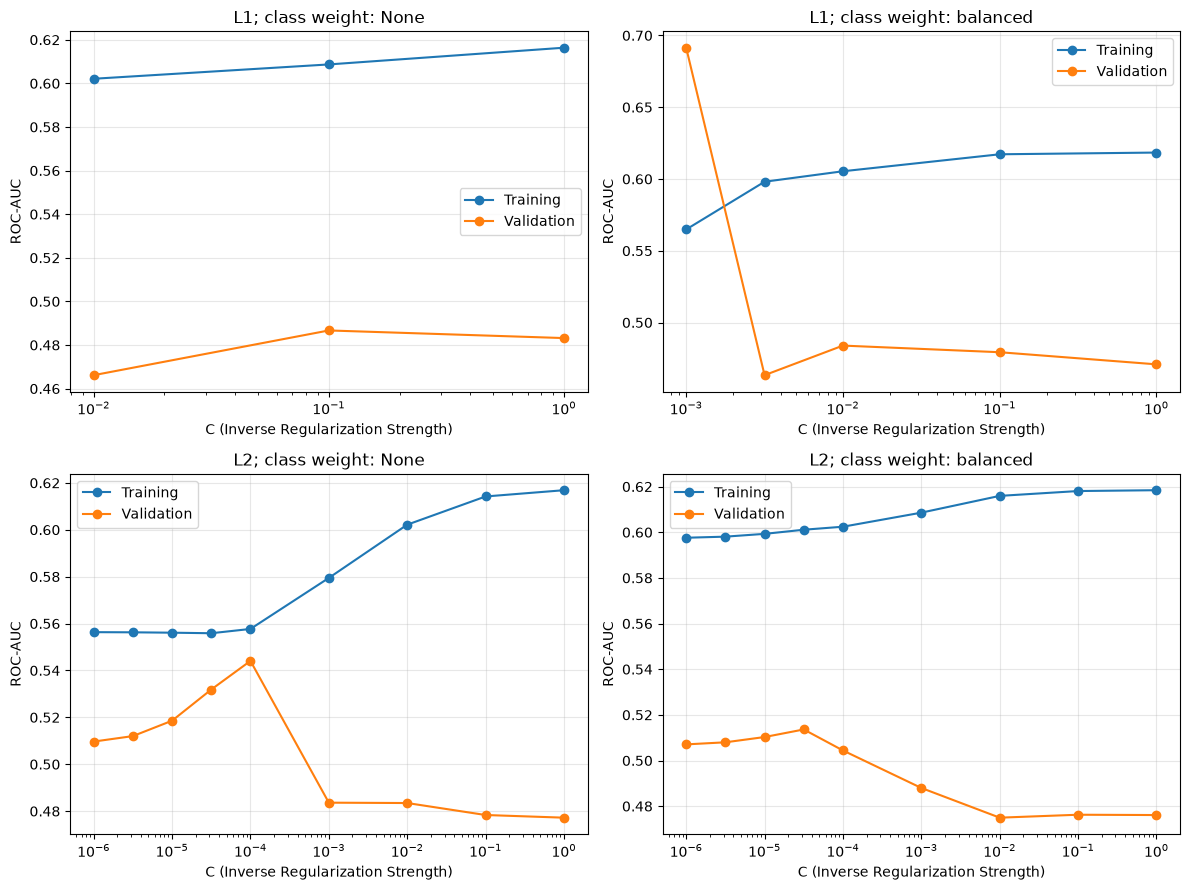

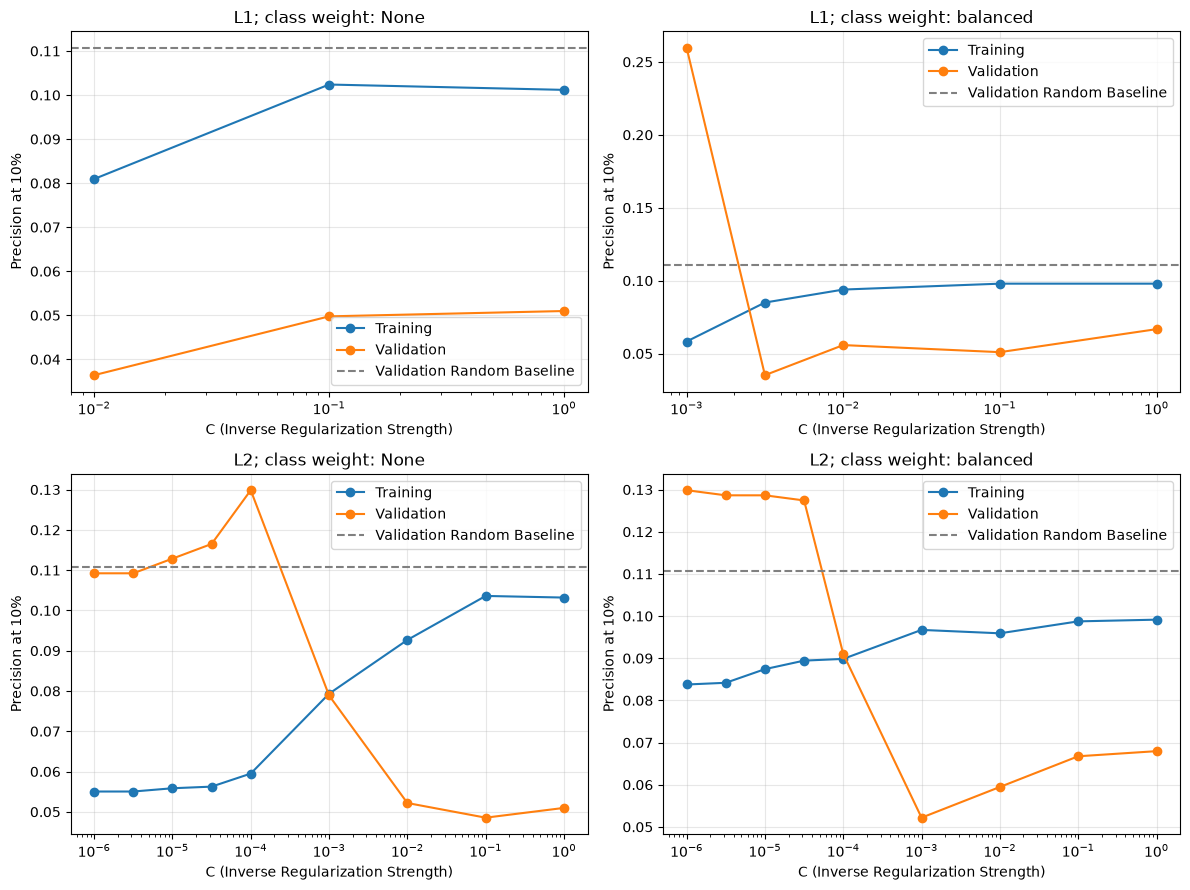

In [36]:
############################## L1 and L2 Complexity Fitting Graphs ################################

for metric in ['ROC-AUC', 'Precision at 10%']:
    plt.figure(figsize=(12, 9))
    for i, penalty in enumerate(['L1', 'L2']):
        for j, weight in enumerate(['None', 'balanced']):
            results = lr_search_log[(lr_search_log['Penalty'] == penalty) &
                                    (lr_search_log['Class Weight'] == weight) &
                                    lr_search_log['Converged']].sort_values('C')
            plt.subplot(2, 2, i * 2 + j + 1)
            # Constant-score fits are excluded from the ranking comparison.
            plotted = results.copy()
            plotted.loc[plotted['Active Coefficients'] == 0, ['Training ' + metric, 'Validation ' + metric]] = np.nan
            plt.plot(plotted['C'], plotted['Training ' + metric], 'o-', label='Training')
            plt.plot(plotted['C'], plotted['Validation ' + metric], 'o-', label='Validation')
            if metric == 'Precision at 10%':
                plt.axhline(y_validation.mean(), color='gray', linestyle='--', label='Validation Random Baseline')
            plt.xscale('log')
            plt.xlabel('C (Inverse Regularization Strength)')
            plt.ylabel(metric)
            plt.title(penalty + '; class weight: ' + weight)
            plt.legend()
            plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


#### Feature selection as a controlled comparison

The proposal motivates excluding `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, and `nr.employed` because their distributions may vary across campaigns. This is a hypothesis tested with validation data, not an assumption that economic indicators are always harmful. Retain all other predictors and tune the same C/weight grid with the same selection rule. This is a feature-group ablation: its comparison answers whether excluding this group improves validation targeting, while the main model retains all 20 predictors.

In [37]:
############################## Train and Tune the Feature Subset ################################

macro_features = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
subset_numeric_features = [col for col in numeric_features if col not in macro_features]
subset_preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), subset_numeric_features),
    ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features)
])
X_train_subset = subset_preprocessor.fit_transform(X_train.drop(columns=macro_features))
X_validation_subset = subset_preprocessor.transform(X_validation.drop(columns=macro_features))
subset_models, subset_search_log, subset_results, subset_search_ranges = search_lr(X_train_subset, X_validation_subset)
best_subset_lr = subset_models[int(subset_results.iloc[0]['Model ID'])]
subset_validation_prob = best_subset_lr.predict_proba(X_validation_subset)[:, 1]
display(subset_search_ranges)
display(subset_results.round(5))
comparison_columns = ['Penalty', 'C', 'Class Weight', 'Active Coefficients', 'Encoded Features',
                      'Validation ROC-AUC', 'Validation Precision at 10%', 'Validation Lift at 10%']
validation_feature_comparison = pd.DataFrame([
    lr_tuning_results.iloc[0][comparison_columns], subset_results.iloc[0][comparison_columns]
], index=['Main: all 20 inputs', 'Alternative: 15 inputs'])
display(validation_feature_comparison)
print('All penalties, feature sets, C ranges and weights are frozen before test scoring.')


/private/tmp/celeste-e-model-env/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,Penalty,Coarse Best C,Fine Minimum C,Fine Maximum C
0,L1,0.01000,0.001000,0.1000
1,L2,0.00001,0.000001,0.0001


,Model ID,Stage,Penalty,C,Class Weight,Training ROC-AUC,Training Precision at 10%,Validation ROC-AUC,Validation AP,Validation Precision at 10%,Validation Capture at 10%,Validation Lift at 10%,Active Coefficients,Encoded Features,Iterations,Converged
0,15,Coarse,L2,0.00001,balanced,0.58342,0.07042,0.60685,0.19901,0.26456,0.23904,2.38890,44,44,4,True
1,27,Fine,L2,0.00000,balanced,0.58288,0.07163,0.60369,0.19913,0.26456,0.23904,2.38890,44,44,4,True
2,25,Fine,L2,0.00000,balanced,0.58269,0.07163,0.60234,0.19880,0.26456,0.23904,2.38890,44,44,3,True
3,29,Fine,L2,0.00003,balanced,0.58482,0.06961,0.61177,0.19826,0.26335,0.23794,2.37794,44,44,4,True
4,31,Fine,L2,0.00010,balanced,0.58811,0.07123,0.61690,0.19449,0.25485,0.23026,2.30123,44,44,5,True
5,12,Fine,L1,0.03162,None,0.59677,0.08256,0.60836,0.18773,0.22937,0.20724,2.07111,7,44,21,True
6,5,Coarse,L1,0.01000,balanced,0.59878,0.08863,0.61335,0.17744,0.21117,0.19079,1.90674,10,44,25,True
7,11,Fine,L1,0.00316,balanced,0.57967,0.06677,0.58097,0.17348,0.20510,0.18531,1.85195,4,44,8,True
8,6,Coarse,L1,0.10000,None,0.60641,0.09713,0.60966,0.17054,0.20267,0.18311,1.83003,21,44,53,True
9,17,Coarse,L2,0.00100,balanced,0.60220,0.08337,0.60708,0.16607,0.19175,0.17325,1.73140,44,44,6,True


,Penalty,C,Class Weight,Active Coefficients,Encoded Features,Validation ROC-AUC,Validation Precision at 10%,Validation Lift at 10%
Main: all 20 inputs,L1,0.00100,balanced,2,49,0.69146,0.259709,2.345067
Alternative: 15 inputs,L2,0.00001,balanced,44,44,0.60685,0.264563,2.388900


All penalties, feature sets, C ranges and weights are frozen before test scoring.


In [38]:
############################## Compare Penalties and Selected Features ################################

penalty_comparison_rows = []
selected_encoded_tables = []
group_selection_rows = []
for name, results, models, preprocessor, raw_numeric in [
    ('20 inputs', lr_tuning_results, lr_models, lr_preprocessor, numeric_features),
    ('15 inputs', subset_results, subset_models, subset_preprocessor, subset_numeric_features)
]:
    for penalty in ['L1', 'L2']:
        winner = results[results['Penalty'] == penalty].iloc[0]
        model = models[int(winner['Model ID'])]
        row = winner.to_dict()
        row['Feature Set'] = name
        penalty_comparison_rows.append(row)
        table = pd.DataFrame({
            'Feature Set': name, 'Penalty': penalty,
            'Encoded Feature': preprocessor.get_feature_names_out(),
            'Coefficient': model.coef_[0],
            'Active': np.abs(model.coef_[0]) > 1e-10
        })
        selected_encoded_tables.append(table)
        # Numeric columns first, then the retained dummy columns for each category.
        encoder = preprocessor.named_transformers_['categorical']
        lengths = [1] * len(raw_numeric) + [len(values) - 1 for values in encoder.categories_]
        names = raw_numeric + categorical_features
        offset = 0
        for original_name, length in zip(names, lengths):
            active = int(table['Active'].iloc[offset:offset + length].sum())
            group_selection_rows.append({'Feature Set': name, 'Penalty': penalty,
                                         'Original Predictor': original_name, 'Encoded Columns': length,
                                         'Active Columns': active, 'Fully Excluded': active == 0})
            offset += length
        assert offset == len(table)
penalty_comparison = pd.DataFrame(penalty_comparison_rows)
selected_encoded_features = pd.concat(selected_encoded_tables, ignore_index=True)
group_selection = pd.DataFrame(group_selection_rows)
display(penalty_comparison[['Feature Set', 'Penalty', 'C', 'Class Weight', 'Active Coefficients',
                            'Encoded Features', 'Validation Precision at 10%', 'Validation Lift at 10%', 'Validation ROC-AUC']])
print('L1 retained encoded columns:')
display(selected_encoded_features[(selected_encoded_features['Penalty'] == 'L1') & selected_encoded_features['Active']])
print('Original-predictor level selection (a dropped reference dummy does not mean its predictor was excluded):')
display(group_selection[group_selection['Penalty'] == 'L1'])


,Feature Set,Penalty,C,Class Weight,Active Coefficients,Encoded Features,Validation Precision at 10%,Validation Lift at 10%,Validation ROC-AUC
0,20 inputs,L1,0.001000,balanced,2,49,0.259709,2.345067,0.691460
1,20 inputs,L2,0.000100,None,49,49,0.129854,1.172534,0.544077
2,15 inputs,L1,0.031623,None,7,44,0.229369,2.071111,0.608355
3,15 inputs,L2,0.000010,balanced,44,44,0.264563,2.388900,0.606850


L1 retained encoded columns:


,Feature Set,Penalty,Encoded Feature,Coefficient,Active
5,20 inputs,L1,numeric__cons.conf.idx,-0.016656,True
7,20 inputs,L1,numeric__nr.employed,0.002666,True
98,15 inputs,L1,numeric__age,-0.044606,True
99,15 inputs,L1,numeric__campaign,-0.051397,True
102,15 inputs,L1,numeric__pdays_clean,0.010833,True
130,15 inputs,L1,categorical__contact_telephone,-0.154719,True
133,15 inputs,L1,categorical__month_may,-0.387513,True
135,15 inputs,L1,categorical__month_oct,1.202478,True
136,15 inputs,L1,categorical__day_of_week_mon,-0.038134,True


Original-predictor level selection (a dropped reference dummy does not mean its predictor was excluded):


,Feature Set,Penalty,Original Predictor,Encoded Columns,Active Columns,Fully Excluded
0,20 inputs,L1,age,1,0,True
1,20 inputs,L1,campaign,1,0,True
2,20 inputs,L1,previous,1,0,True
3,20 inputs,L1,emp.var.rate,1,0,True
4,20 inputs,L1,cons.price.idx,1,0,True
5,20 inputs,L1,cons.conf.idx,1,1,False
6,20 inputs,L1,euribor3m,1,0,True
7,20 inputs,L1,nr.employed,1,1,False
8,20 inputs,L1,previously_contacted,1,0,True
9,20 inputs,L1,pdays_clean,1,0,True


#### Complexity of the 15 Predictor Model
Training versus validation performance helps distinguish model fit from generalization. A very strong penalty can underfit; weaker penalties allow larger or more active coefficients. These curves describe the examined candidates and do not establish a universal overfitting threshold.

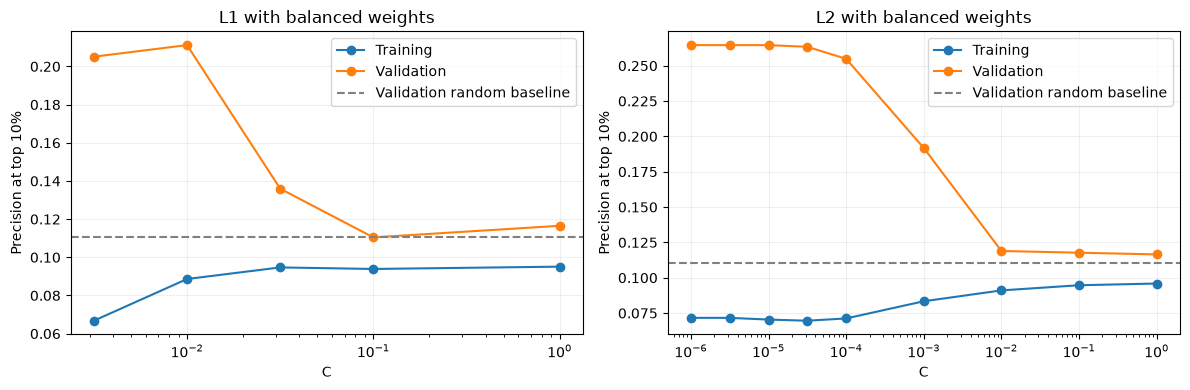

,Feature,Coefficient,Absolute coefficient
35,categorical__month_may,-0.007073,0.007073
32,categorical__contact_telephone,-0.005992,0.005992
33,categorical__month_jul,0.004592,0.004592
0,numeric__age,-0.004450,0.004450
1,numeric__campaign,-0.004034,0.004034
4,numeric__pdays_clean,0.002315,0.002315
37,categorical__month_oct,0.002117,0.002117
3,numeric__previously_contacted,0.001903,0.001903
26,categorical__default_unknown,-0.001797,0.001797
41,categorical__day_of_week_wed,0.001687,0.001687


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, penalty in zip(axes, ["L1", "L2"]):
    rows = subset_search_log[(subset_search_log.Penalty == penalty) &
                            (subset_search_log["Class Weight"] == "balanced") &
                            subset_search_log.Converged].sort_values("C")
    for column, label in [("Training Precision at 10%", "Training"),
                           ("Validation Precision at 10%", "Validation")]:
        values = rows[column].where(rows["Active Coefficients"] > 0)
        ax.semilogx(rows.C, values, "o-", label=label)
    ax.axhline(y_validation.mean(), color="gray", linestyle="--", label="Validation random baseline")
    ax.set(title=penalty + " with balanced weights", xlabel="C", ylabel="Precision at top 10%")
    ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

selected_lr_row = subset_results.iloc[0]
assert selected_lr_row.Penalty == "L2" and np.isclose(selected_lr_row.C, 0.00001)
assert best_subset_lr.class_weight == "balanced"
model_validation_scores["Logistic Regression"] = score_frame(
    y_validation, subset_validation_prob, best_subset_lr.predict(X_validation_subset))
lr_coefficients = pd.DataFrame({"Feature": subset_preprocessor.get_feature_names_out(),
                                "Coefficient": best_subset_lr.coef_[0]})
lr_coefficients["Absolute coefficient"] = lr_coefficients.Coefficient.abs()
display(lr_coefficients.sort_values("Absolute coefficient", ascending=False).head(12))


Regularized coefficients describe fitted associations, not causal effects or statistical significance. Numeric coefficients refer to a one-training-standard-deviation increase; categorical coefficients compare with omitted reference categories. Class weighting changes the fitted objective, so positive-class scores should not automatically be treated as calibrated probabilities.

### 4B k Nearest Neighbors
k-NN ranks records using proximity in the standardized and one-hot encoded feature space. Positive-class oversampling is restricted to the training data. The supplied implementation fits preprocessing on the oversampled training distribution; validation and test remain untouched.

The group compares k = 9, 15, 25, uniform versus distance weighting, and Manhattan versus Euclidean distance. Selection uses Validation Precision at the top 823 records, matching the supplied notebook. The final setting is k=25, uniform weighting and Euclidean distance (p=2). This is the best setting within the examined grid, not a global optimum.

The supplied notebook selects this setting with a reported Validation Precision@823 of 18.35%. Replaying the search in a different numerical environment can change distance ties and rankings. The grid below reports the current refit separately; we retain the group’s documented setting rather than changing it after reviewing test results.

In [40]:
############################ Remove Macroeconomic Variables ############################

macro_features = [
    'emp.var.rate',
    'cons.price.idx',
    'cons.conf.idx',
    'euribor3m',
    'nr.employed'
]

X_train_reduced = X_train.drop(columns=macro_features)
X_validation_reduced = X_validation.drop(columns=macro_features)
X_test_reduced = X_test.drop(columns=macro_features)

print("Original predictors:", X_train.shape[1])
print("Reduced predictors:", X_train_reduced.shape[1])

print("Train:", X_train_reduced.shape)
print("Validation:", X_validation_reduced.shape)
print("Test:", X_test_reduced.shape)

Original predictors: 20
Reduced predictors: 15
Train: (24705, 15)
Validation: (8235, 15)
Test: (8236, 15)


In [41]:
############################ Reduced Feature Lists ############################

categorical_features_reduced = [
    'job',
    'marital',
    'education',
    'default',
    'housing',
    'loan',
    'contact',
    'month',
    'day_of_week',
    'poutcome'
]

numeric_features_reduced = [
    'age',
    'campaign',
    'previous',
    'previously_contacted',
    'pdays_clean'
]

print("Categorical:", len(categorical_features_reduced))
print("Numeric:", len(numeric_features_reduced))
print("Total:", len(categorical_features_reduced) + len(numeric_features_reduced))

Categorical: 10
Numeric: 5
Total: 15


In [42]:
############################ Reduced k-NN Preprocessing ############################

knn_preprocessor_reduced = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features_reduced),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features_reduced)
    ]
)

print("Reduced k-NN preprocessing created.")

Reduced k-NN preprocessing created.


In [43]:
############################ Balance Reduced Training Data ############################
from sklearn.utils import resample
train_knn_reduced = X_train_reduced.copy()
train_knn_reduced["y"] = y_train.values

majority_reduced = train_knn_reduced[train_knn_reduced["y"] == 0]
minority_reduced = train_knn_reduced[train_knn_reduced["y"] == 1]

minority_upsampled_reduced = resample(
    minority_reduced,
    replace=True,
    n_samples=len(majority_reduced),
    random_state=42
)

train_knn_balanced_reduced = pd.concat([
    majority_reduced,
    minority_upsampled_reduced
]).sample(frac=1, random_state=42)

X_train_balanced_reduced = train_knn_balanced_reduced.drop(columns=["y"])
y_train_balanced_reduced = train_knn_balanced_reduced["y"]

print(y_train_balanced_reduced.value_counts())

y
1    23517
0    23517
Name: count, dtype: int64


In [44]:
reported_knn_tuning = pd.DataFrame([{'k': 25, 'weights': 'uniform', 'p': 2, 'Reported Validation Precision@823': 0.183475, 'Reported Validation F1': 0.197589, 'Reported Validation ROC-AUC': 0.539122}, {'k': 25, 'weights': 'uniform', 'p': 1, 'Reported Validation Precision@823': 0.165249, 'Reported Validation F1': 0.199441, 'Reported Validation ROC-AUC': 0.540443}, {'k': 25, 'weights': 'distance', 'p': 2, 'Reported Validation Precision@823': 0.155529, 'Reported Validation F1': 0.197389, 'Reported Validation ROC-AUC': 0.537155}, {'k': 15, 'weights': 'uniform', 'p': 2, 'Reported Validation Precision@823': 0.149453, 'Reported Validation F1': 0.20049, 'Reported Validation ROC-AUC': 0.538555}, {'k': 15, 'weights': 'distance', 'p': 1, 'Reported Validation Precision@823': 0.148238, 'Reported Validation F1': 0.198426, 'Reported Validation ROC-AUC': 0.536703}, {'k': 9, 'weights': 'uniform', 'p': 2, 'Reported Validation Precision@823': 0.147023, 'Reported Validation F1': 0.200278, 'Reported Validation ROC-AUC': 0.541148}, {'k': 15, 'weights': 'uniform', 'p': 1, 'Reported Validation Precision@823': 0.147023, 'Reported Validation F1': 0.19936, 'Reported Validation ROC-AUC': 0.538011}, {'k': 15, 'weights': 'distance', 'p': 2, 'Reported Validation Precision@823': 0.147023, 'Reported Validation F1': 0.201164, 'Reported Validation ROC-AUC': 0.536389}, {'k': 25, 'weights': 'distance', 'p': 1, 'Reported Validation Precision@823': 0.145808, 'Reported Validation F1': 0.199314, 'Reported Validation ROC-AUC': 0.539515}, {'k': 9, 'weights': 'uniform', 'p': 1, 'Reported Validation Precision@823': 0.144593, 'Reported Validation F1': 0.196146, 'Reported Validation ROC-AUC': 0.5408}, {'k': 9, 'weights': 'distance', 'p': 2, 'Reported Validation Precision@823': 0.138518, 'Reported Validation F1': 0.182668, 'Reported Validation ROC-AUC': 0.539396}, {'k': 9, 'weights': 'distance', 'p': 1, 'Reported Validation Precision@823': 0.137303, 'Reported Validation F1': 0.179441, 'Reported Validation ROC-AUC': 0.540031}])
print("Supplied notebook validation tuning results")
display(reported_knn_tuning.sort_values("Reported Validation Precision@823", ascending=False))
print("Recomputed validation tuning results in this runtime")
knn_candidates = []
knn_fitted = {}
for k in [9, 15, 25]:
    for weights in ["uniform", "distance"]:
        for p in [1, 2]:
            candidate = Pipeline([
                ("preprocessor", clone(knn_preprocessor_reduced)),
                ("knn", KNeighborsClassifier(n_neighbors=k, weights=weights, p=p, n_jobs=4))
            ])
            candidate.fit(X_train_balanced_reduced, y_train_balanced_reduced)
            scores = candidate.predict_proba(X_validation_reduced)[:, 1]
            labels = (scores > 0.50).astype(int)
            owner_ranking = pd.DataFrame({"actual": y_validation.values,
                                          "probability": scores}).sort_values("probability", ascending=False)
            owner_precision = owner_ranking.head(int(len(y_validation)*.10)).actual.mean()
            common = top824_metrics(y_validation, scores)
            knn_candidates.append({"k": k, "weights": weights, "p": p,
                "Validation Precision@823": owner_precision,
                "Validation Precision@824": common["Precision@824"],
                "Subscribers captured@824": common["Subscribers captured"],
                "Validation Lift@824": common["Lift@824"],
                "Validation F1": f1_score(y_validation, labels, zero_division=0),
                "Validation ROC-AUC": roc_auc_score(y_validation, scores)})
            knn_fitted[(k, weights, p)] = candidate
            print("Evaluated k-NN", k, weights, p)
knn_tuning = pd.DataFrame(knn_candidates).sort_values(
    "Validation Precision@823", ascending=False)
display(knn_tuning)
print("Highest Precision@823 setting in this runtime:", knn_tuning.iloc[0][["k", "weights", "p"]].to_dict())
print("Group selected setting retained: k=25, uniform, p=2")
knn_final_reduced = knn_fitted[(25, "uniform", 2)]
knn_validation_probability = knn_final_reduced.predict_proba(X_validation_reduced)[:, 1]
model_validation_scores["k-NN"] = score_frame(y_validation, knn_validation_probability,
                                             knn_final_reduced.predict(X_validation_reduced))


Supplied notebook validation tuning results


,k,weights,p,Reported Validation Precision@823,Reported Validation F1,Reported Validation ROC-AUC
0,25,uniform,2,0.183475,0.197589,0.539122
1,25,uniform,1,0.165249,0.199441,0.540443
2,25,distance,2,0.155529,0.197389,0.537155
3,15,uniform,2,0.149453,0.200490,0.538555
4,15,distance,1,0.148238,0.198426,0.536703
5,9,uniform,2,0.147023,0.200278,0.541148
6,15,uniform,1,0.147023,0.199360,0.538011
7,15,distance,2,0.147023,0.201164,0.536389
8,25,distance,1,0.145808,0.199314,0.539515
9,9,uniform,1,0.144593,0.196146,0.540800


Recomputed validation tuning results in this runtime


Evaluated k-NN 9 uniform 1


Evaluated k-NN 9 uniform 2


...

Evaluated k-NN 25 uniform 2


Evaluated k-NN 25 distance 1


Evaluated k-NN 25 distance 2


,k,weights,p,Validation Precision@823,Validation Precision@824,Subscribers captured@824,Validation Lift@824,Validation F1,Validation ROC-AUC
8,25,uniform,1,0.165249,0.138350,114,1.249242,0.199441,0.540443
9,25,uniform,2,0.164034,0.152913,126,1.380741,0.196983,0.538865
11,25,distance,2,0.155529,0.155340,128,1.402657,0.197121,0.536899
5,15,uniform,2,0.149453,0.145631,120,1.314991,0.199782,0.538783
1,9,uniform,2,0.148238,0.151699,125,1.369782,0.200418,0.541411
6,15,distance,1,0.148238,0.148058,122,1.336908,0.198426,0.536703
4,15,uniform,1,0.147023,0.140777,116,1.271158,0.199360,0.538011
7,15,distance,2,0.147023,0.148058,122,1.336908,0.200443,0.536581
10,25,distance,1,0.145808,0.146845,121,1.325949,0.199314,0.539515
0,9,uniform,1,0.144593,0.145631,120,1.314991,0.196146,0.540800


Highest Precision@823 setting in this runtime: {'k': 25, 'weights': 'uniform', 'p': 1}
Group selected setting retained: k=25, uniform, p=2


#### k NN Complexity and Distance Sensitivity
Smaller k permits more local variation and can fit duplicated training neighbors closely. Larger k smooths scores and may lose useful local patterns. The following plot uses the final 15-predictor, oversampled approach. The selected k lies at the upper end of the examined grid; future tuning can investigate a wider range without using the current test outcomes.

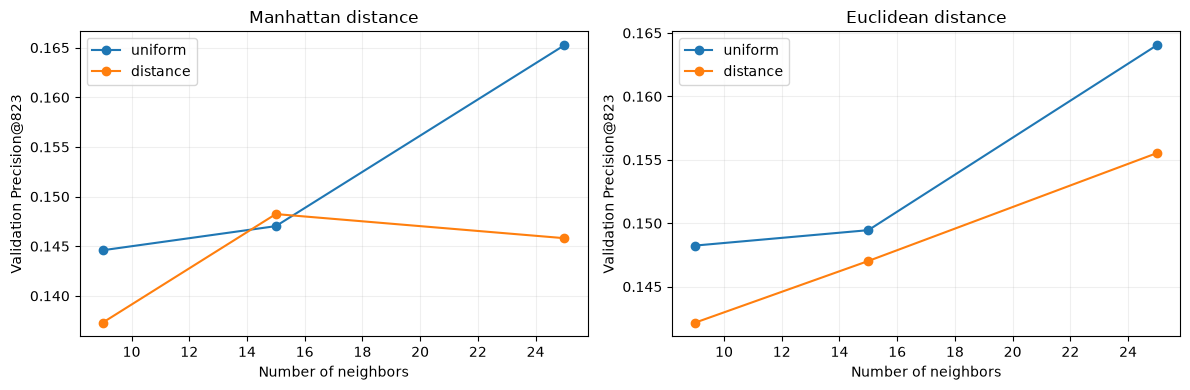

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, p in zip(axes, [1, 2]):
    for weights in ["uniform", "distance"]:
        rows = knn_tuning[(knn_tuning.p == p) & (knn_tuning.weights == weights)].sort_values("k")
        ax.plot(rows.k, rows["Validation Precision@823"], "o-", label=weights)
    ax.set(title={1: "Manhattan distance", 2: "Euclidean distance"}[p],
           xlabel="Number of neighbors", ylabel="Validation Precision@823")
    ax.grid(alpha=.2); ax.legend()
plt.tight_layout(); plt.show()


### 4C Decision Tree
CART captures nonlinear interactions through split rules. We use 15 predictors, one-hot encoded categoricals, numeric passthrough, balanced class weights, minimum leaf size 50 and random_state=42. Depths 2 through 10 are compared on the shared validation set using exactly 824 records and score descending, record ID ascending ordering.

Depth 7 has the highest Validation Precision@824. Validation ROC-AUC instead peaks at depth 4. We select depth 7 for the declared business objective; its validation lift below 1 remains a limitation.

,max_depth,Training ROC-AUC,Validation ROC-AUC,Subscribers captured,Precision@824,Lift@824
0,2,0.572827,0.550435,26,0.031553,0.284915
1,3,0.580902,0.549558,25,0.030340,0.273956
2,4,0.597621,0.556053,30,0.036408,0.328748
3,5,0.618065,0.536286,22,0.026699,0.241082
4,6,0.629602,0.509590,34,0.041262,0.372581
5,7,0.648544,0.515375,58,0.070388,0.635579
6,8,0.663895,0.529619,41,0.049757,0.449289
7,9,0.681212,0.504829,57,0.069175,0.624621
8,10,0.697611,0.506715,43,0.052184,0.471205


Selected depth by Validation Precision@824: 7
Highest validation AUC depth: 4


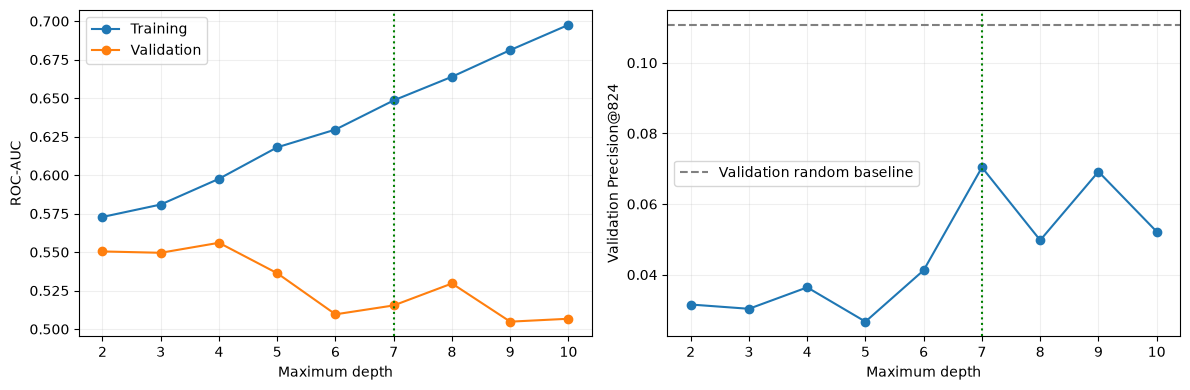

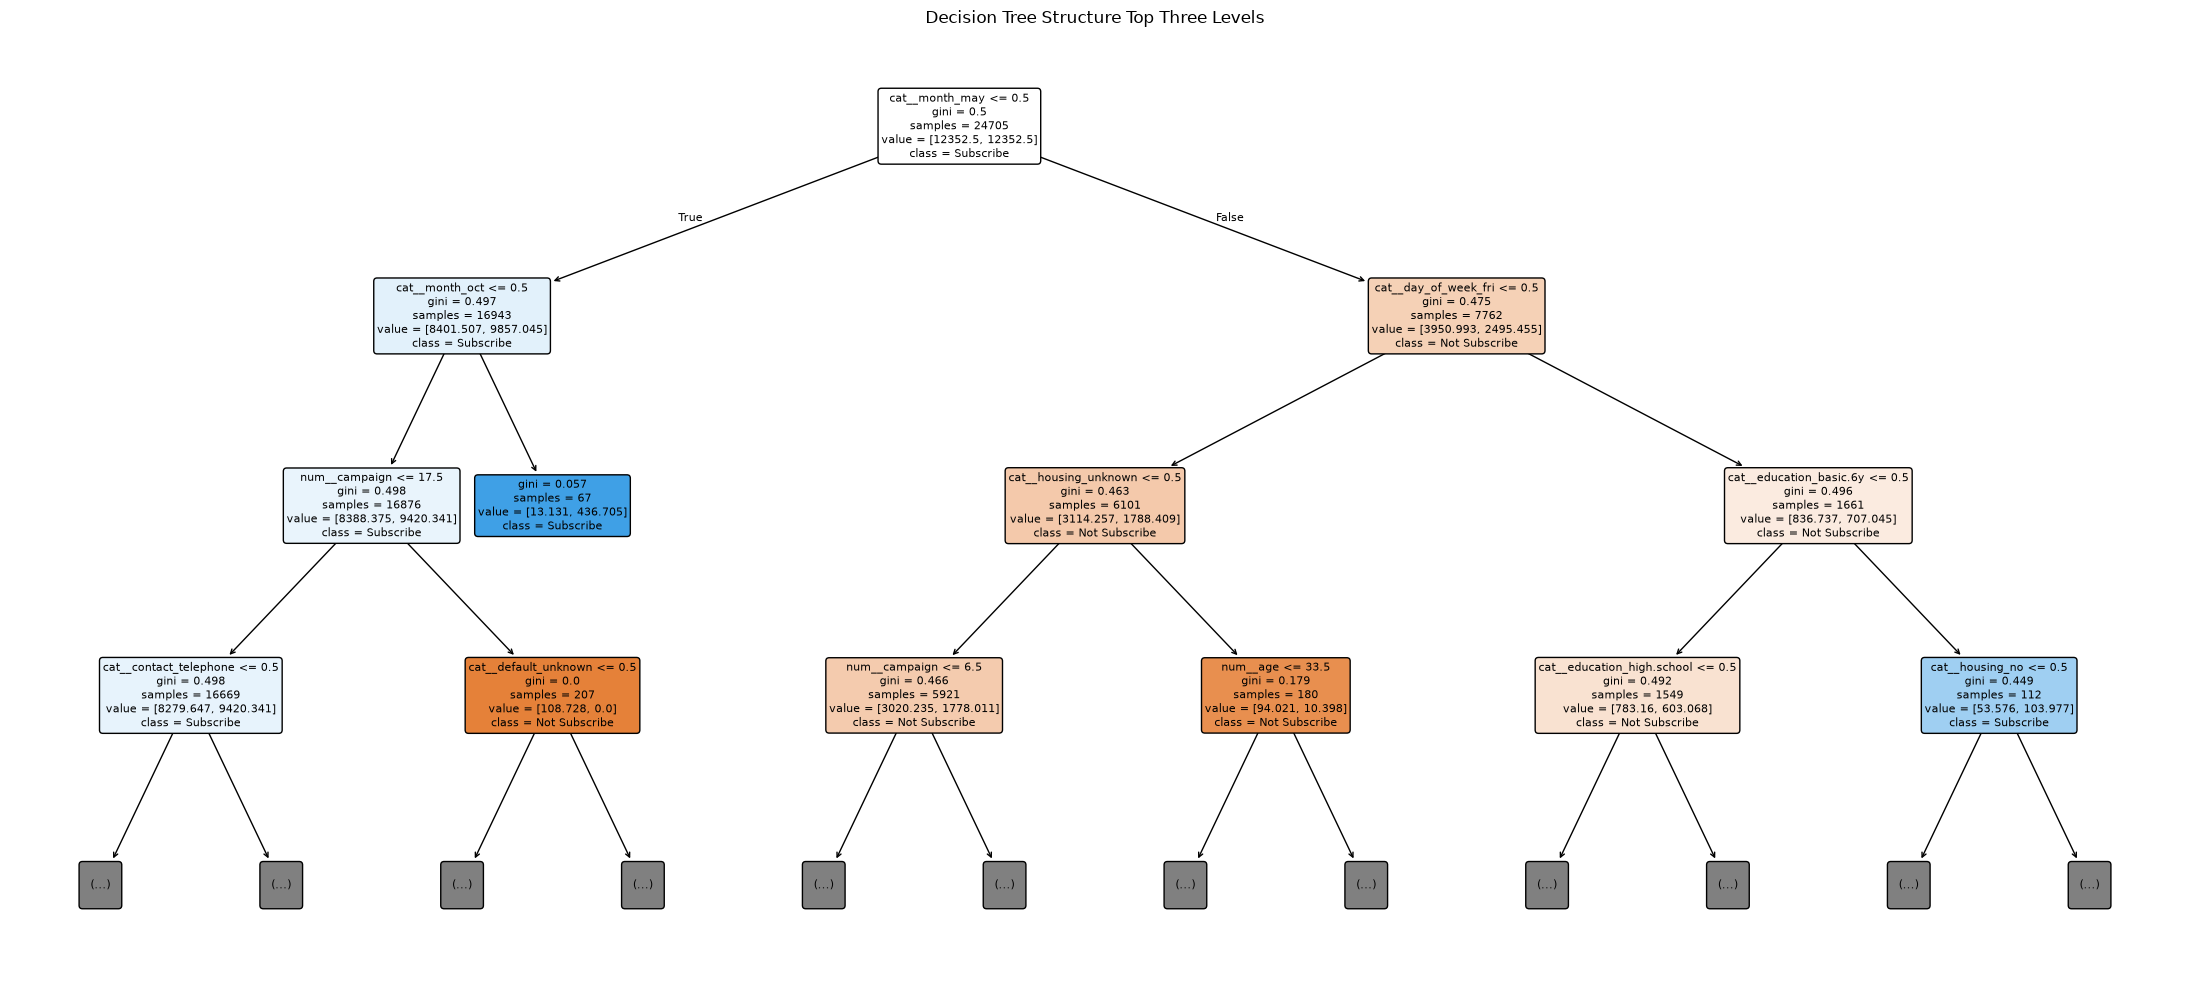

In [46]:
dt_rows = []
dt_fitted = {}
for depth in range(2, 11):
    dt_preprocessor = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", drop=None), categorical_features),
        ("num", "passthrough", [c for c in numeric_features if c not in macro_features])])
    candidate = Pipeline([("preprocessor", dt_preprocessor),
        ("classifier", DecisionTreeClassifier(criterion="gini", max_depth=depth,
             min_samples_leaf=50, class_weight="balanced", random_state=42))])
    candidate.fit(X_train, y_train)
    validation_probability = candidate.predict_proba(X_validation)[:, 1]
    dt_rows.append({"max_depth": depth,
        "Training ROC-AUC": roc_auc_score(y_train, candidate.predict_proba(X_train)[:, 1]),
        "Validation ROC-AUC": roc_auc_score(y_validation, validation_probability),
        **top824_metrics(y_validation, validation_probability)})
    dt_fitted[depth] = candidate

dt_tuning = pd.DataFrame(dt_rows)
display(dt_tuning)
selected_depth = int(dt_tuning.loc[dt_tuning["Precision@824"].idxmax(), "max_depth"])
optimal_tree_pipeline = dt_fitted[selected_depth]
assert selected_depth == 7
print("Selected depth by Validation Precision@824:", selected_depth)
print("Highest validation AUC depth:", int(dt_tuning.loc[dt_tuning["Validation ROC-AUC"].idxmax(), "max_depth"]))
model_validation_scores["Decision Tree"] = score_frame(y_validation,
    optimal_tree_pipeline.predict_proba(X_validation)[:, 1], optimal_tree_pipeline.predict(X_validation))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(dt_tuning.max_depth, dt_tuning["Training ROC-AUC"], "o-", label="Training")
axes[0].plot(dt_tuning.max_depth, dt_tuning["Validation ROC-AUC"], "o-", label="Validation")
axes[0].set(ylabel="ROC-AUC", xlabel="Maximum depth"); axes[0].legend()
axes[1].plot(dt_tuning.max_depth, dt_tuning["Precision@824"], "o-")
axes[1].axhline(y_validation.mean(), color="gray", linestyle="--", label="Validation random baseline")
axes[1].set(ylabel="Validation Precision@824", xlabel="Maximum depth"); axes[1].legend()
for ax in axes: ax.axvline(selected_depth, color="green", linestyle=":"); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

from sklearn import tree
plt.figure(figsize=(22, 10))
tree.plot_tree(optimal_tree_pipeline.named_steps["classifier"], max_depth=3,
    feature_names=optimal_tree_pipeline.named_steps["preprocessor"].get_feature_names_out(),
    class_names=["Not Subscribe", "Subscribe"], filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree Structure Top Three Levels"); plt.tight_layout(); plt.show()


### Final Models and Test Scoring
All settings below are selected from validation and are frozen before this test scoring step. Models remain fitted on training records only. Historical test results have been examined during project iterations; these results should therefore be treated as descriptive rather than a fresh independent confirmation.

The final business comparison uses the teammate’s supplied k-NN test scores, after validating IDs and labels, to preserve the group’s documented result. Refitted k-NN scores are retained and compared explicitly in the reproducibility checks. LR and DT use refitted scores that match their handoffs. This source choice does not reselect hyperparameters or reverse scores using test labels.

In [47]:
display(pd.DataFrame([
    {"Model": "Logistic Regression", "Predictors": 15, "Setting": "L2, C=0.00001, balanced"},
    {"Model": "k-NN", "Predictors": 15, "Setting": "k=25, uniform, Euclidean, training oversampling"},
    {"Model": "Decision Tree", "Predictors": 15, "Setting": "depth=7, min_samples_leaf=50, balanced"}]))

X_test_subset = subset_preprocessor.transform(X_test.drop(columns=macro_features))
model_test_scores["Logistic Regression"] = score_frame(y_test,
    best_subset_lr.predict_proba(X_test_subset)[:, 1], best_subset_lr.predict(X_test_subset))
model_test_scores["k-NN"] = score_frame(y_test,
    knn_final_reduced.predict_proba(X_test_reduced)[:, 1], knn_final_reduced.predict(X_test_reduced))
model_test_scores["Decision Tree"] = score_frame(y_test,
    optimal_tree_pipeline.predict_proba(X_test)[:, 1], optimal_tree_pipeline.predict(X_test))
refitted_test_scores = {name: frame.copy() for name, frame in model_test_scores.items()}
knn_handoff_path = Path("reference_scores/knn_final_reduced_predictions.csv")
knn_handoff = pd.read_csv(knn_handoff_path).rename(columns={"Unnamed: 0": "record_id",
    "actual": "actual_y", "knn_probability": "predicted_score", "knn_prediction": "predicted_label"})
knn_handoff = knn_handoff.sort_values("record_id").reset_index(drop=True)
assert np.array_equal(knn_handoff.record_id, X_test.index)
assert np.array_equal(knn_handoff.actual_y, y_test)
model_test_scores["k-NN"] = knn_handoff
score_sources = pd.DataFrame([
    {"Model": "Logistic Regression", "Test score source": "Refitted model matching teammate export"},
    {"Model": "k-NN", "Test score source": "Teammate final 15-predictor test export"},
    {"Model": "Decision Tree", "Test score source": "Refitted model matching teammate export"}])
display(score_sources)
refitted_test_scores["k-NN"].to_csv(OUTPUT_DIR/"knn_refitted_test_scores.csv", index=False)

for period, frames in [("validation", model_validation_scores), ("test", model_test_scores)]:
    for name, frame in frames.items():
        frame.to_csv(OUTPUT_DIR / (name.replace(" ", "_") + "_" + period + "_scores.csv"), index=False)
lr_search_log.to_csv(OUTPUT_DIR / "lr20_validation_search.csv", index=False)
subset_search_log.to_csv(OUTPUT_DIR / "lr15_validation_search.csv", index=False)
knn_tuning.to_csv(OUTPUT_DIR / "knn_validation_search.csv", index=False)
dt_tuning.to_csv(OUTPUT_DIR / "dt_validation_search.csv", index=False)


,Model,Predictors,Setting
0,Logistic Regression,15,"L2, C=0.00001, balanced"
1,k-NN,15,"k=25, uniform, Euclidean, training oversampling"
2,Decision Tree,15,"depth=7, min_samples_leaf=50, balanced"


/private/tmp/celeste-e-model-env/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,Model,Test score source
0,Logistic Regression,Refitted model matching teammate export
1,k-NN,Teammate final 15-predictor test export
2,Decision Tree,Refitted model matching teammate export


## 5 Evaluation
### Customer Prioritization
The bank's decision is which records to prioritize at a fixed contact capacity. We compare the final three models on the same test records and use 824 selections for all models. Precision and lift at capacity measure historical targeting efficiency; ROC-AUC and F1 provide complementary diagnostics.

### Evaluation Design
The business decision is which records to prioritize when contact capacity is limited. We use the shared chronological split: 24,705 training records, 8,235 validation records, and 8,236 test records. For the illustrative 10% capacity, the selection size is rounded up: 824 records in both validation and test.

Ranking uses score descending and prepared record ID ascending for equal scores. The ID is the row index in the shared prepared dataset, preserved through the split. It identifies matching records; it does not measure subscription propensity. Every score file must contain the complete corresponding evaluation set with matching IDs and actual labels. Records represent client campaign records rather than guaranteed unique customers or independent calls.

Validation supports model selection in the Modeling section. The test comparison below describes historical performance of the selected models. It does not establish performance on current customers or subscriptions caused by outreach.

In [48]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

DATA_DIR = Path.cwd()
RESULTS_DIR = DATA_DIR / "business_evaluation_results"
RESULTS_DIR.mkdir(exist_ok=True)
CONTACT_SHARE = 0.10

test_scores = {name: frame.sort_values("record_id").reset_index(drop=True)
               for name, frame in model_test_scores.items()}
validation_scores = {name: frame.sort_values("record_id").reset_index(drop=True)
                     for name, frame in model_validation_scores.items()}
for frames, expected, actual in [(test_scores, X_test.index, y_test),
                                 (validation_scores, X_validation.index, y_validation)]:
    assert len(frames) == 3
    for name, frame in frames.items():
        assert np.array_equal(frame.record_id, expected), name + ": record IDs do not match"
        assert np.array_equal(frame.actual_y, actual), name + ": labels do not match"
test_reference = next(iter(test_scores.values()))
validation_reference = next(iter(validation_scores.values()))
display(pd.DataFrame([{ "Model": name, "Test records": len(frame),
                        "Actual subscribers": int(frame.actual_y.sum()),
                        "Subscription rate": frame.actual_y.mean()}
                     for name, frame in test_scores.items()]))


,Model,Test records,Actual subscribers,Subscription rate
0,Logistic Regression,8236,2539,0.308281
1,k-NN,8236,2539,0.308281
2,Decision Tree,8236,2539,0.308281


### Ranking Metrics
At a fixed capacity k:

- **Precision@k** = recorded subscribers among the selected records ÷ k.
- **Cumulative gains@k** = recorded subscribers among the selected records ÷ all recorded subscribers in the same evaluation set.
- **Lift@k** = Precision@k ÷ the overall subscription rate in that evaluation set.
- **Random expectation** = k × that evaluation set's subscription rate.

Precision and gains have different denominators. The random baseline must match the records from which selection is made. Test prevalence is 2,539 / 8,236 = 30.83%; the full dataset's subscription rate is not the appropriate test baseline.

In [49]:
def ranked_scores(frame):
    return frame.sort_values(["predicted_score", "record_id"], ascending=[False, True])

def ranking_metrics(frame, capacity):
    ordered = ranked_scores(frame)
    selected = ordered.head(capacity)
    captured = int(selected.actual_y.sum())
    prevalence = frame.actual_y.mean()
    return {
        "Capacity": capacity,
        "Subscribers captured": captured,
        "Precision@capacity": captured / capacity,
        "Cumulative gains@capacity": captured / int(frame.actual_y.sum()),
        "Lift@capacity": (captured / capacity) / prevalence,
        "Random expected subscribers": capacity * prevalence,
        "Additional historical subscribers identified": captured - capacity * prevalence,
    }

def comparison_table(frames):
    return pd.DataFrame([
        {"Model": name, **ranking_metrics(frame, math.ceil(len(frame) * CONTACT_SHARE))}
        for name, frame in frames.items()
    ])

test_comparison = comparison_table(test_scores)
test_comparison.to_csv(RESULTS_DIR / "test_ranking_comparison.csv", index=False)
formatted_comparison = test_comparison.copy()
for column, pattern in {"Precision@capacity": "{:.2%}",
                        "Cumulative gains@capacity": "{:.2%}",
                        "Lift@capacity": "{:.2f}",
                        "Random expected subscribers": "{:.2f}",
                        "Additional historical subscribers identified": "{:.2f}"}.items():
    formatted_comparison[column] = formatted_comparison[column].map(pattern.format)
display(formatted_comparison)
if validation_scores:
    validation_comparison = comparison_table(validation_scores)
    validation_comparison.to_csv(RESULTS_DIR / "validation_ranking_comparison.csv", index=False)


,Model,Capacity,Subscribers captured,Precision@capacity,Cumulative gains@capacity,Lift@capacity,Random expected subscribers,Additional historical subscribers identified
0,Logistic Regression,824,550,66.75%,21.66%,2.17,254.02,295.98
1,k-NN,824,523,63.47%,20.60%,2.06,254.02,268.98
2,Decision Tree,824,341,41.38%,13.43%,1.34,254.02,86.98


### Classification Diagnostics
The models first produce scores for each record. F1 summarizes yes/no classifications at a classification threshold, ROC-AUC examines discrimination across the entire score ranking, and top-capacity yield examines only the first k ranked records. These measures can favor different models because they evaluate different decision rules.

The table uses the supplied classification labels where available; otherwise it applies a 0.50 score threshold and explicitly identifies this rule. Positive-class scores are useful for ranking but class weighting or oversampling does not automatically produce calibrated probabilities.

In [50]:
classification_rows = []
for name, frame in test_scores.items():
    if "predicted_label" in frame.columns:
        predictions = frame.predicted_label.astype(int)
        rule = "Supplied classification prediction"
    else:
        predictions = (frame.predicted_score >= 0.50).astype(int)
        rule = "Score threshold 0.50"
    classification_rows.append({
        "Model": name, "Classification rule": rule,
        "Accuracy": accuracy_score(frame.actual_y, predictions),
        "Precision": precision_score(frame.actual_y, predictions, zero_division=0),
        "Recall": recall_score(frame.actual_y, predictions),
        "F1": f1_score(frame.actual_y, predictions),
        "ROC-AUC": roc_auc_score(frame.actual_y, frame.predicted_score),
    })
classification_results = pd.DataFrame(classification_rows)
classification_results.to_csv(RESULTS_DIR / "test_classification_metrics.csv", index=False)
display(classification_results)


,Model,Classification rule,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,Supplied classification prediction,0.647766,0.451028,0.656558,0.534723,0.695326
1,k-NN,Supplied classification prediction,0.558402,0.375567,0.652619,0.476766,0.637739
2,Decision Tree,Supplied classification prediction,0.603813,0.387856,0.493108,0.434195,0.562699


### Model Comparison Curves
The following charts compare the score data provided by the Modeling section. The capacity comparison, cumulative gains, cumulative response and lift curves measure targeting performance. ROC curves provide complementary evidence about overall discrimination. Equal scores follow the stated record-ID rule; a sharp curve segment can reflect selection within a tied block rather than distinctions made by the model.

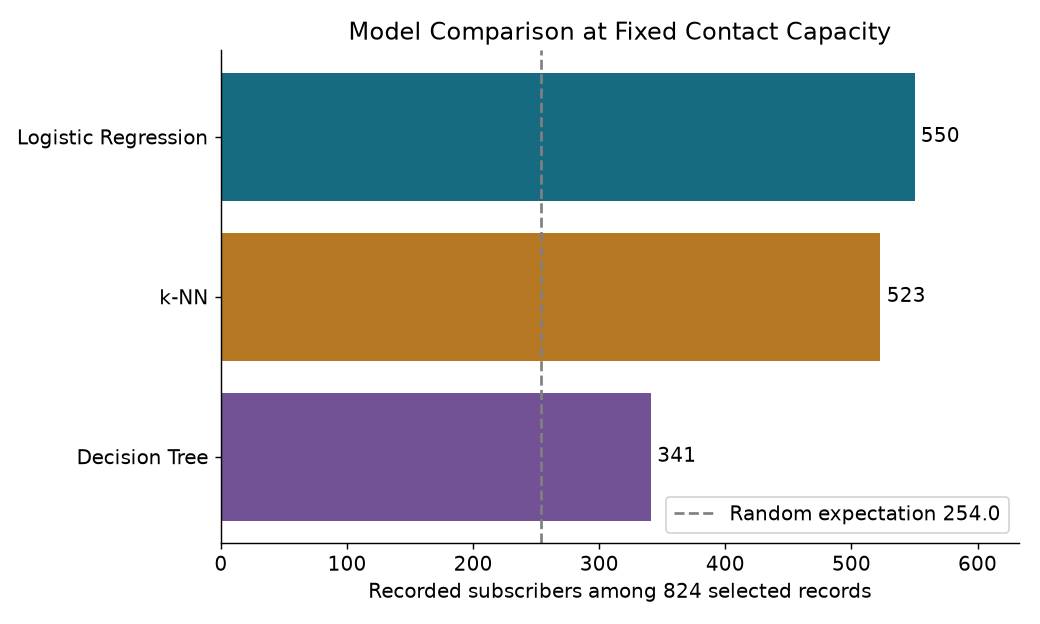

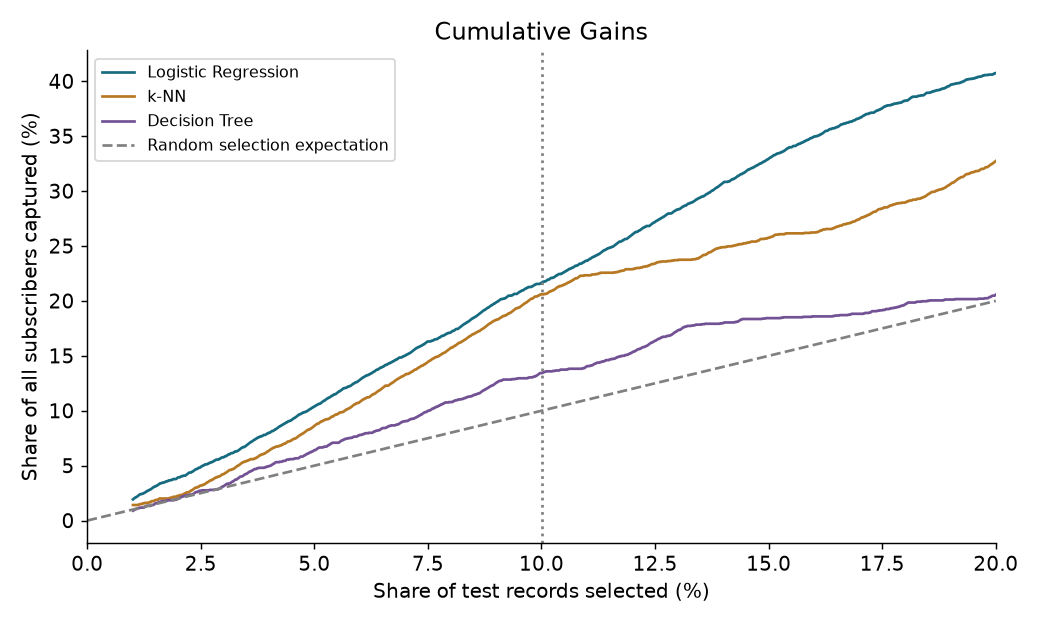

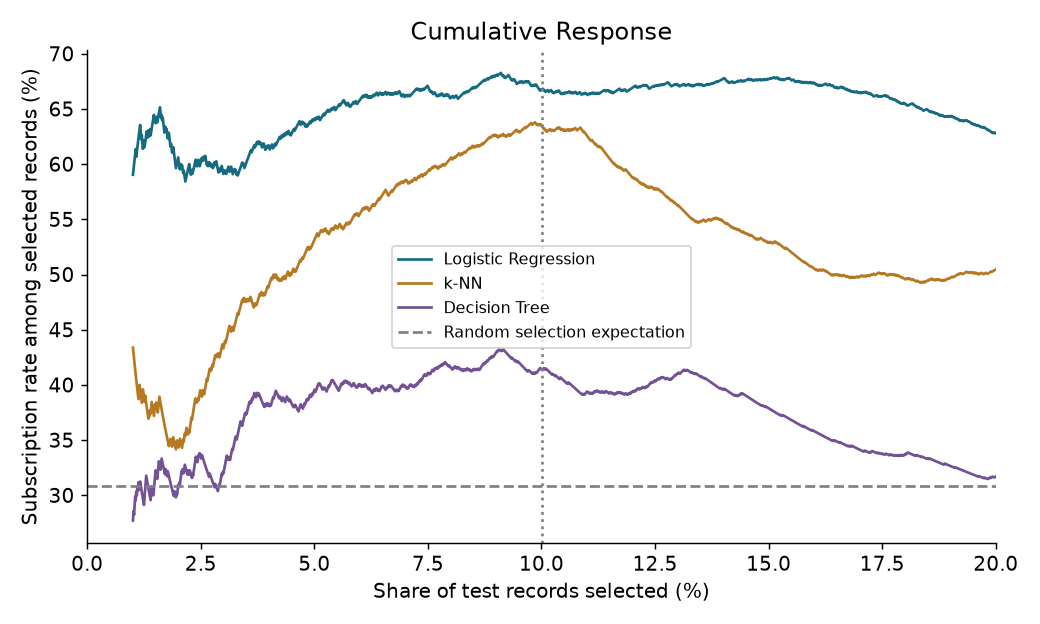

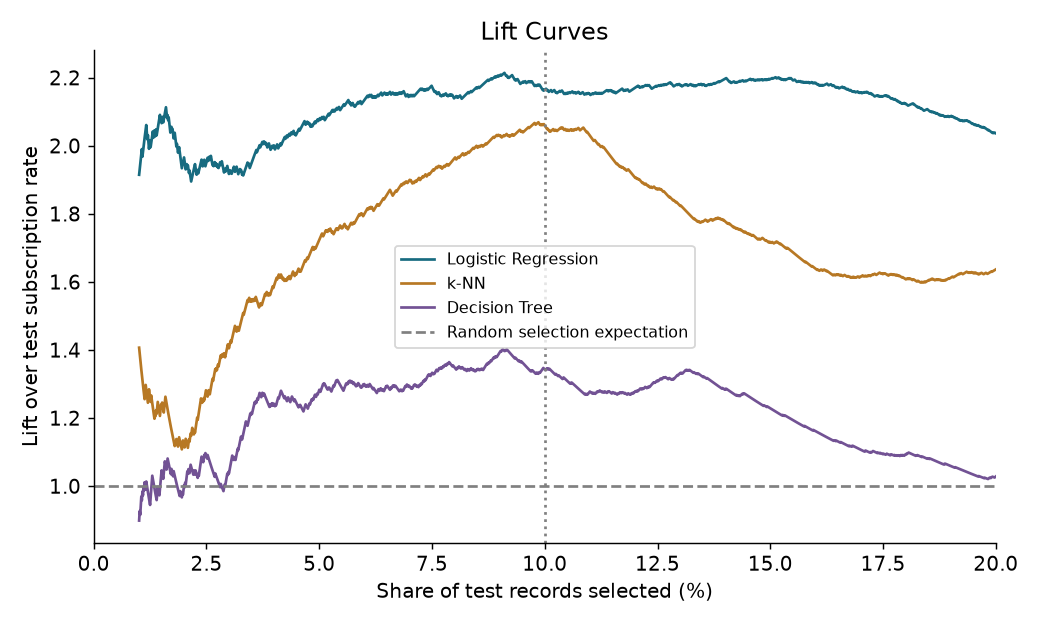

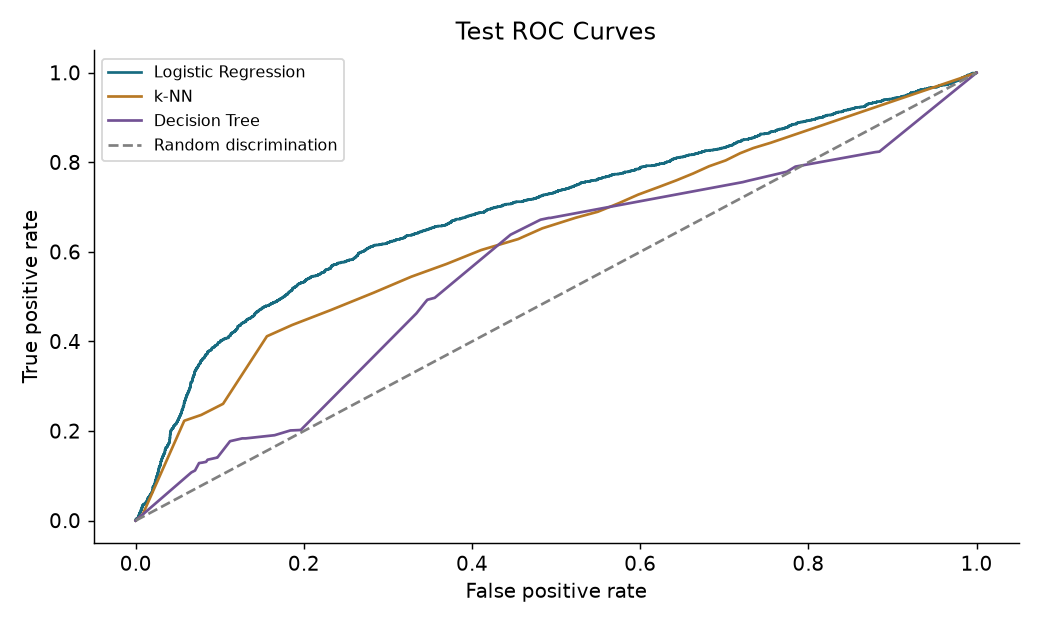

In [51]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from io import BytesIO

plt.rcParams.update({"font.size": 11, "figure.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
colors = {"Logistic Regression": "#176b80", "k-NN": "#b77824", "Decision Tree": "#725294"}

def show_and_save(fig, filename):
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / filename, dpi=170)
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=130)
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

capacity = math.ceil(len(test_reference) * CONTACT_SHARE)
base_rate = test_reference.actual_y.mean()
random_expected = capacity * base_rate
fig, ax = plt.subplots(figsize=(8, 4.8))
for _, row in test_comparison.iterrows():
    bar = ax.barh(row["Model"], row["Subscribers captured"], color=colors[row["Model"]])
    ax.text(row["Subscribers captured"] + 5, bar[0].get_y() + bar[0].get_height()/2,
            str(int(row["Subscribers captured"])), va="center")
ax.axvline(random_expected, color="gray", linestyle="--", label=f"Random expectation {random_expected:.1f}")
ax.invert_yaxis()
ax.set(xlim=(0, test_comparison["Subscribers captured"].max()*1.15),
       xlabel=f"Recorded subscribers among {capacity} selected records", title="Model Comparison at Fixed Contact Capacity")
ax.legend()
show_and_save(fig, "contact_capacity_comparison.png")

for kind in ["gains", "response", "lift", "roc"]:
    fig, ax = plt.subplots(figsize=(8, 4.8))
    for name, frame in test_scores.items():
        if kind == "roc":
            x, y, _ = roc_curve(frame.actual_y, frame.predicted_score)
        else:
            ordered = ranked_scores(frame)
            contacts = np.arange(1, len(frame)+1)
            hits = ordered.actual_y.cumsum().to_numpy()
            x = contacts / len(frame) * 100
            y = (hits/frame.actual_y.sum()*100 if kind == "gains" else
                 hits/contacts*100 if kind == "response" else hits/contacts/frame.actual_y.mean())
            mask = (x >= 1) & (x <= 20.1)
            x, y = x[mask], y[mask]
        ax.plot(x, y, color=colors[name], label=name)
    if kind == "roc":
        ax.plot([0, 1], [0, 1], "--", color="gray", label="Random discrimination")
        ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Test ROC Curves")
    else:
        baseline = [0, 20] if kind == "gains" else [base_rate*100]*2 if kind == "response" else [1, 1]
        ax.plot([0, 20], baseline, "--", color="gray", label="Random selection expectation")
        ax.axvline(capacity/len(test_reference)*100, color="gray", linestyle=":")
        ax.set(xlim=(0, 20), xlabel="Share of test records selected (%)",
               ylabel={"gains": "Share of all subscribers captured (%)",
                       "response": "Subscription rate among selected records (%)",
                       "lift": "Lift over test subscription rate"}[kind],
               title={"gains": "Cumulative Gains", "response": "Cumulative Response", "lift": "Lift Curves"}[kind])
    ax.legend(fontsize=9)
    show_and_save(fig, f"{kind}.png")


### Business Case
The bank's potential value is identifying more likely subscribers within the same contact capacity. This is a historical targeting-efficiency comparison. Monetary ROI requires contact costs, net customer value, implementation costs and evidence of incremental subscriptions caused by the outreach policy.

,Contact capacity,LR subscribers identified,Random expected subscribers,Additional historical subscribers identified,Higher historical yield
0,824,550,254.023312,295.976688,1.165156


At the same capacity of **824 records**, Logistic Regression identifies **550** recorded subscribers, compared with a random expectation of **254.0**. This is approximately **296 additional historical subscribers identified** and a **116.5% higher historical yield**. These counts do not establish causal incremental subscriptions or actual monetary ROI.

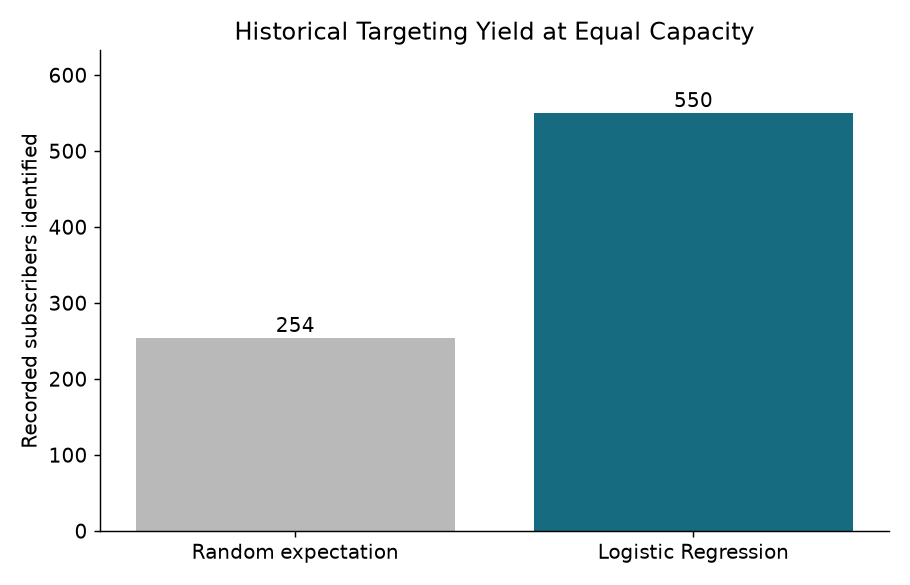

In [52]:
lr_row = test_comparison.loc[test_comparison.Model == "Logistic Regression"].iloc[0]
yield_increase = lr_row["Subscribers captured"] / lr_row["Random expected subscribers"] - 1
business_case = {
    "Contact capacity": int(lr_row["Capacity"]),
    "LR subscribers identified": int(lr_row["Subscribers captured"]),
    "Random expected subscribers": float(lr_row["Random expected subscribers"]),
    "Additional historical subscribers identified": float(lr_row["Additional historical subscribers identified"]),
    "Higher historical yield": yield_increase,
}
display(pd.DataFrame([business_case]))
display(Markdown(
    f"At the same capacity of **{business_case['Contact capacity']} records**, Logistic Regression identifies "
    f"**{business_case['LR subscribers identified']}** recorded subscribers, compared with a random expectation of "
    f"**{business_case['Random expected subscribers']:.1f}**. This is approximately "
    f"**{business_case['Additional historical subscribers identified']:.0f} additional historical subscribers identified** "
    f"and a **{yield_increase:.1%} higher historical yield**. These counts do not establish causal incremental subscriptions or actual monetary ROI."
))
fig, ax = plt.subplots(figsize=(7, 4.5))
values = [business_case["Random expected subscribers"], business_case["LR subscribers identified"]]
bars = ax.bar(["Random expectation", "Logistic Regression"], values, color=["#B9B9B9", colors["Logistic Regression"]])
for bar, value in zip(bars, values):
    ax.text(bar.get_x()+bar.get_width()/2, value+8, f"{value:.0f}", ha="center")
ax.set(ylim=(0, max(values)*1.15), ylabel="Recorded subscribers identified", title="Historical Targeting Yield at Equal Capacity")
show_and_save(fig, "business_value.png")


### Interpretation and Limitations
Logistic Regression identifies 550 recorded subscribers in the top 824 test records, with Precision@824 of 66.75%, cumulative gains of 21.66% and lift of 2.17. k-NN identifies 523, with Precision@824 of 63.47% and lift of 2.06 under the same selection rule. This is 27 fewer recorded subscribers than Logistic Regression. Decision Tree (max_depth=7) identifies 341 recorded subscribers, with Precision@824 of 41.38%, cumulative gains of 13.43% and lift of 1.34. The evidence supports Logistic Regression as a pilot candidate and k-NN as a challenger; it does not establish general algorithm superiority.

Subscription rates differ across the chronological training, validation and test periods (4.81%, 11.07% and 30.83%). Performance may depend on campaign composition and economic conditions. A single temporal evaluation does not demonstrate stability across future periods. Historical test results have already been reviewed, so independent future evaluation is required for confirmation.

Equal-score records cannot be distinguished by model scores. Record-ID ordering provides a reproducible capacity rule, but selecting different records within the boundary tie can change captured subscribers. The tie policy should therefore be defined before operational use.

The dataset lacks actual contact costs and customer profitability. Historical subscribers identified cannot be treated as causal incremental sales, and the analysis does not measure realized ROI.

### Interpretation and Limitations
Logistic Regression identifies 550 recorded subscribers in the top 824 test records, with Precision@824 of 66.75%, cumulative gains of 21.66% and lift of 2.17. k-NN identifies 523 (63.47% precision, lift 2.06); Decision Tree identifies 341 (41.38% precision, lift 1.34). This supports Logistic Regression as a controlled-pilot candidate and k-NN as a challenger, rather than general algorithm superiority.

Decision Tree's validation lift is only 0.64, below the random baseline, despite its test lift of 1.34. Subscription prevalence changes from 4.81% in training to 11.07% in validation and 30.83% in test. Higher raw yield across these periods should not be interpreted as equivalent improvement in ranking skill. Future evaluation is needed to assess stability.

Equal-score records cannot be distinguished by model score. Prepared-ID ordering is reproducible but does not indicate customer value within a tie. Contact costs, profitability and causal outreach effects are absent, so historical subscribers identified do not establish realized monetary ROI.

## 6 Deployment
### Proposed Marketing Workflow
Prepare an eligible customer list and honor contact preferences; generate pre-contact features; apply the frozen preprocessing and model; rank within the approved capacity and tie policy; obtain manager review; record contacts, costs and matured outcomes. Customer-level IDs are needed for unique-customer and frequency constraints.

### Controlled Pilot and Financial Evaluation
Pilot Logistic Regression with k-NN as a challenger. Randomly assign eligible customers to comparable policy pools, comparing model targeting with random targeting at equal capacity using the same offer and outcome window. Record outcomes for all assigned customers. Estimate incremental subscriptions and actual costs before forecasting net financial benefit or monetary ROI.

### Risks and Mitigation
- **Feature availability:** Campaign-related fields must be known before outreach. Verify definitions at scoring time; substituting planned values for historical values changes meaning and requires revalidation.
- **Temporal drift:** Monitor prevalence, input distributions, unseen categories, matured Precision@capacity and lift. Revalidate on recent data and retrain when warranted.
- **Tied scores and capacity:** Define the tie policy before observing outcomes and assess its effect on targeting decisions.
- **Uncertain impact:** Limit initial rollout, use a controlled pilot and measure incremental outcomes and costs before expansion.

### Ethical Considerations
Restrict customer-data access, minimize data use, honor opt-outs and contact-frequency limits, and maintain human oversight. Review selection rates and outcomes across groups such as age and job for unfair exclusion or excessive targeting. These are proposed safeguards; no deployment or fairness assessment has been completed.

## Reproducibility Checks
Compare refitted selected models with the teammate handoff files using aligned IDs and actual labels. The final business comparison uses the supplied k-NN export; its refitted scores and any differences are reported below. LR and DT use refitted scores matching their exports. Numerical libraries and distance ties may contribute to differences, but the exact cause is not established from the supplied files.

In [53]:
reference_map = {
    ("Logistic Regression", "test"): "logistic_15vars_L2_balanced_test_scores.csv",
    ("Logistic Regression", "validation"): "logistic_15vars_L2_balanced_validation_scores.csv",
    ("k-NN", "test"): "knn_final_reduced_predictions.csv",
    ("Decision Tree", "test"): "dt_test_scores.csv",
    ("Decision Tree", "validation"): "dt_validation_scores.csv",
}
reproduction_rows = []
for (name, period), filename in reference_map.items():
    path = Path("reference_scores") / filename
    if not path.exists():
        continue
    ref = pd.read_csv(path).rename(columns={"Unnamed: 0": "record_id", "actual": "actual_y",
        "knn_probability": "predicted_score", "knn_prediction": "predicted_label"}).sort_values("record_id")
    fitted = (refitted_test_scores if period == "test" else model_validation_scores)[name].sort_values("record_id")
    assert np.array_equal(ref.record_id, fitted.record_id)
    assert np.array_equal(ref.actual_y, fitted.actual_y)
    reproduction_rows.append({"Model": name, "Set": period,
        "Maximum absolute score difference": np.abs(ref.predicted_score.to_numpy()-fitted.predicted_score.to_numpy()).max(),
        "Scores match within 1e-8": np.allclose(ref.predicted_score, fitted.predicted_score, rtol=0, atol=1e-8)})
display(pd.DataFrame(reproduction_rows))
observed = test_comparison.set_index("Model")["Subscribers captured"].to_dict()
assert observed == {"Logistic Regression": 550, "k-NN": 523, "Decision Tree": 341}, observed
assert int(y_test.sum()) == 2539
print("The final evaluation uses aligned test records and reproduces the group reported counts.")
print("k-NN supplied versus refitted test results")
display(pd.DataFrame([
    {"Source": source, **top824_metrics(y_test, frame.predicted_score),
     "ROC-AUC": roc_auc_score(y_test, frame.predicted_score),
     "F1": f1_score(y_test, frame.predicted_label)}
    for source, frame in [("Teammate export", model_test_scores["k-NN"]),
                           ("Refitted model", refitted_test_scores["k-NN"])]]))


,Model,Set,Maximum absolute score difference,Scores match within 1e-8
0,Logistic Regression,test,3.330669e-16,True
1,Logistic Regression,validation,3.330669e-16,True
2,k-NN,test,1.200000e-01,False
3,Decision Tree,test,5.551115e-17,True
4,Decision Tree,validation,5.551115e-17,True


The final evaluation uses aligned test records and reproduces the group reported counts.
k-NN supplied versus refitted test results


,Source,Subscribers captured,Precision@824,Lift@824,ROC-AUC,F1
0,Teammate export,523,0.634709,2.058866,0.637739,0.476766
1,Refitted model,523,0.634709,2.058866,0.637885,0.477204


## Sources
Data: UCI Bank Marketing, `bank-additional-full.csv`. Modeling and preparation sources: `Presentation First Three parts+KNN 1.ipynb`, `yerimPresentation First Three parts, tree and precision10.ipynb`, `Project_Logistic_Regression.ipynb`, and the Logistic Regression model-comparison workbook. Business context: Team 10 Business Proposal. Evaluation and Deployment: Celeste Wang's Business Evaluation and Deployment section. Structure reference: course Spotify classification sample. Models and numerical summaries use the group's supplied implementation and final settings; test outcomes do not provide causal evidence of outreach impact.

AI disclosure: ChatGPT was used to help write and debug parts of the code and explanatory text. All analysis decisions, modeling choices and results were reviewed and verified by the team.